# PH3043 — Z-Boson Resonance Analysis

## Notebook 02: Invariant-Mass Distribution and Peak Estimation

### Objective

To investigate the reconstructed dimuon invariant-mass
distribution, identify the Z-boson resonance, estimate
its position and evaluate statistical uncertainty.

The corrected reconstruction from transverse momentum,
pseudorapidity and azimuthal angle is used as the primary
baseline. The Cartesian reconstruction is retained for
comparison.

No additional event-quality cuts are applied to the
initial baseline.

In [1]:
#loading the reconstructed data set

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project folder
PROJECT_ROOT = Path.cwd().parent

# Load reconstructed data
data_file = (
    PROJECT_ROOT /
    "results" /
    "dimuon_reconstructed.csv"
)

df2 = pd.read_csv(data_file)

print("Loaded events:", len(df2))
print("Available columns:")
print(df2.columns.tolist())

display(df2.head())



Loaded events: 83761
Available columns:
['Run', 'Event', 'Q1', 'Q2', 'pt1', 'eta1', 'phi1', 'pt2', 'eta2', 'phi2', 'M', 'M_calc', 'M_alt_corrected', 'M_diff', 'M_alt_corrected_diff', 'pt1_diff', 'pt2_diff']


,Run,Event,Q1,Q2,pt1,eta1,phi1,pt2,eta2,phi2,M,M_calc,M_alt_corrected,M_diff,M_alt_corrected_diff,pt1_diff,pt2_diff
0,166699,835716681,1,-1,4.2116,2.2366,-0.4849,1.2556,2.2683,-1.4488,2.1330,2.145853,2.147495,0.012853,0.014495,9.806248e-07,3.192457e-05
1,166699,836133459,-1,1,2.1479,-2.0159,-2.7753,19.5453,-1.0826,-0.3408,13.6786,13.680958,13.680827,0.002358,0.002227,5.225506e-05,7.185500e-05
2,166699,836165498,1,-1,21.0732,1.5948,-1.1137,2.3864,1.5352,-1.7388,4.3813,4.395351,4.396042,0.014051,0.014742,7.732332e-06,9.153938e-06
3,166699,836249706,1,-1,18.5889,1.6422,1.1923,1.8721,1.9704,1.6393,3.2587,3.273007,3.275025,0.014307,0.016325,9.569638e-05,8.761079e-05
4,166699,835608783,-1,1,11.8194,0.8711,-1.5811,0.9408,2.0107,-1.6559,4.0171,4.026974,4.026392,0.009874,0.009292,7.651471e-05,9.938356e-07


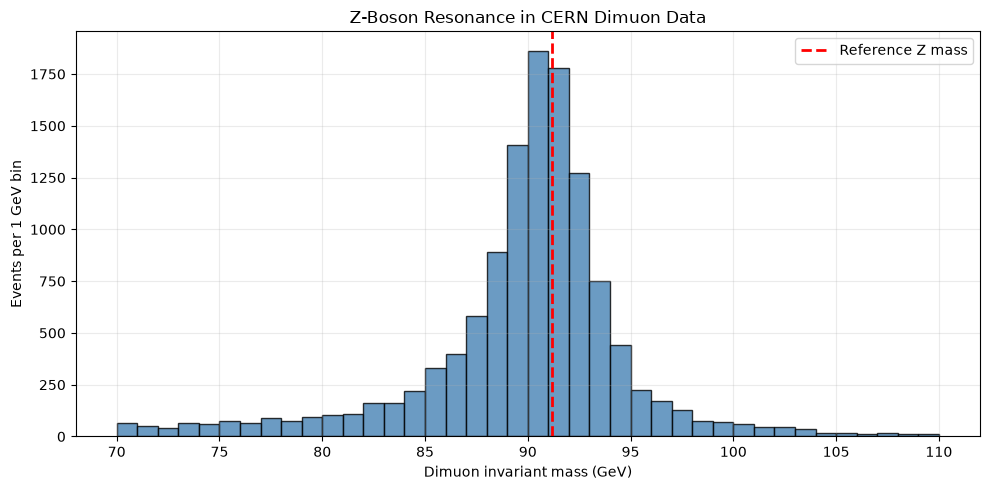

In [3]:
#visualize z resonance

# Select the resonance region
mass = df2["M_alt_corrected"].dropna()

# Fixed histogram edges: 1 GeV bins
edges = np.arange(70, 111, 1)

plt.figure(figsize=(10, 5))

plt.hist(
    mass,
    bins=edges,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    91.1879,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Reference Z mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Events per 1 GeV bin")
plt.title("Z-Boson Resonance in CERN Dimuon Data")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 3. Sensitivity of the Resonance to Histogram Binning

The effect of histogram bin width on the apparent position
and shape of the Z-boson resonance is investigated.

Bin widths of 0.5, 1, 2 and 5 GeV are compared using
the same reconstructed mass dataset.

The most populated bin provides a preliminary peak
descriptor, not a fitted Z-boson mass estimate.

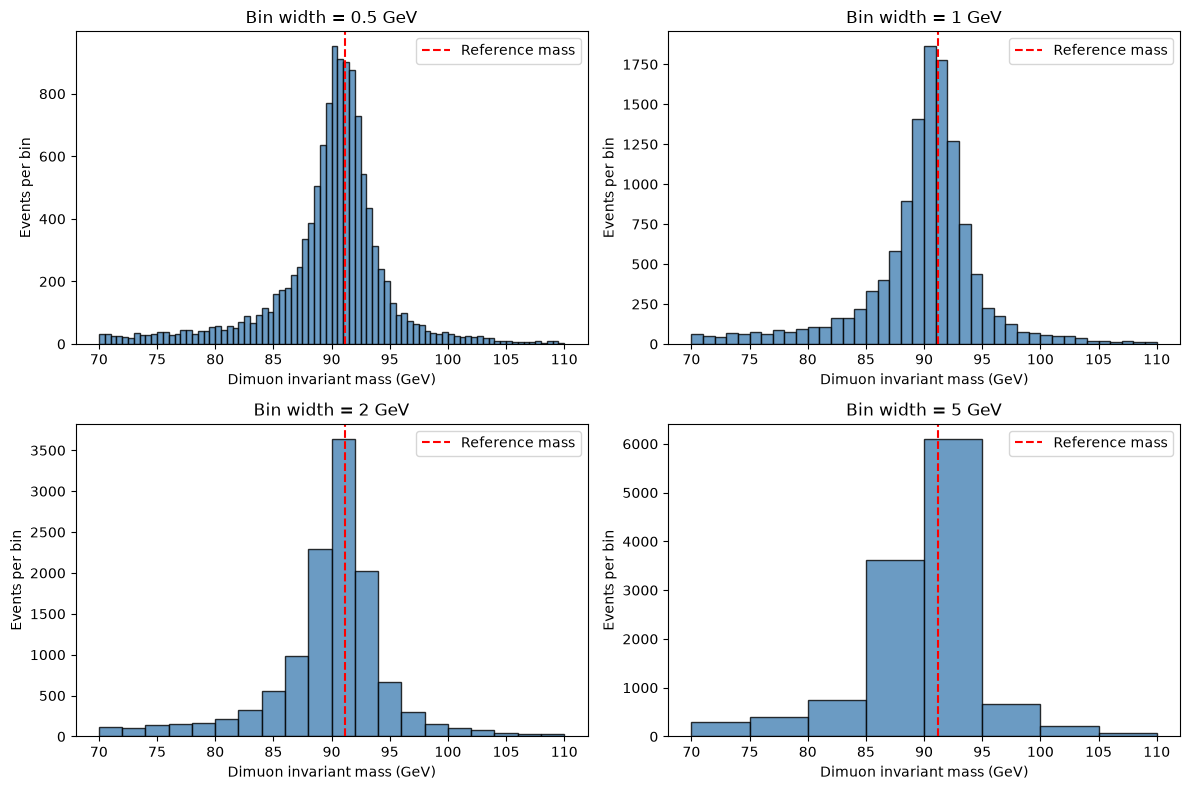

,Bin width (GeV),Peak bin centre (GeV),Peak bin count
0,0.5,90.25,952
1,1.0,90.50,1863
2,2.0,91.00,3642
3,5.0,92.50,6105


In [6]:

# Compare different histogram bin widths

mass = df2["M_alt_corrected"].dropna().to_numpy()

bin_widths = [0.5, 1, 2, 5]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
results = []

for ax, width in zip(axes.flat, bin_widths):

    edges = np.arange(70, 110 + width, width)

    counts, _ = np.histogram(mass, bins=edges)

    peak_index = np.argmax(counts)
    peak_center = (
        edges[peak_index] + edges[peak_index + 1]
    ) / 2

    results.append({
        "Bin width (GeV)": width,
        "Peak bin centre (GeV)": peak_center,
        "Peak bin count": counts[peak_index]
    })

    ax.hist(
        mass,
        bins=edges,
        color="steelblue",
        edgecolor="black",
        alpha=0.8
    )

    ax.axvline(
        91.1879,
        color="red",
        linestyle="--",
        label="Reference mass"
    )

    ax.set_title(f"Bin width = {width} GeV")
    ax.set_xlabel("Dimuon invariant mass (GeV)")
    ax.set_ylabel("Events per bin")
    ax.legend()

plt.tight_layout()
plt.show()

# Compare estimated peak-bin positions
bin_results = pd.DataFrame(results)
display(bin_results)


The peak bin center changes even though we're analyzing the same physical dataset., Because the boundaries change. A wider bin collects more events and its midpoint can be farther from the location of the true resonance maximum.

The larger peak-bin counts are also expected: a 5 GeV bin covers a much wider interval than a 0.5 GeV bin.

,Width (GeV),Peak center (GeV),Absolute difference from PDG (MeV),Peak-center range under bin shifts (MeV)
0,0.25,90.375,812.9,227.273
1,0.50,90.250,937.9,954.545
2,0.75,90.625,562.9,818.182
3,1.00,90.500,687.9,909.091
4,2.00,91.000,187.9,1818.182
5,3.00,89.500,1687.9,2727.273
6,5.00,92.500,1312.1,4545.455


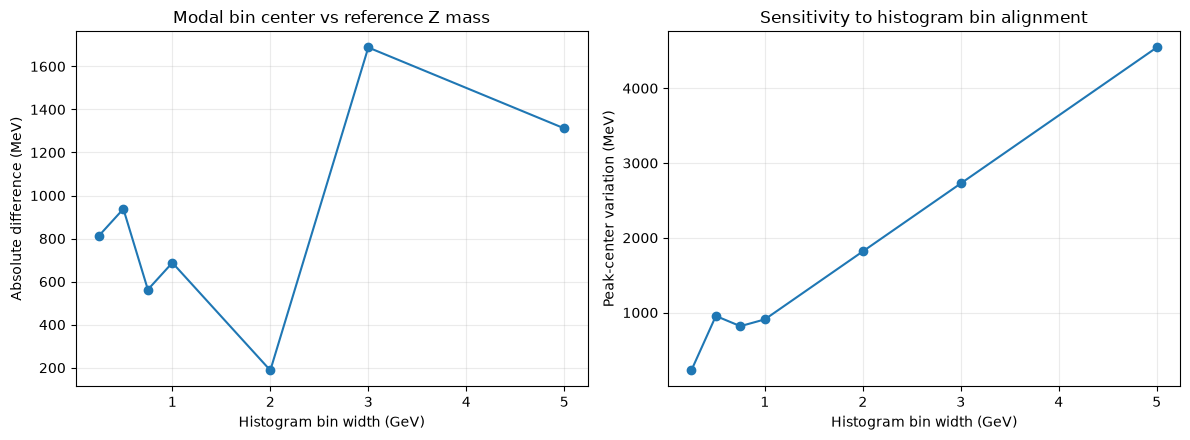

In [117]:
#Can we programmatically select a suitable bin width?
#two checks:
#1. Absolute difference from the reference Z mass: useful for visualizing how the modal bin center varies, but not for choosing the best width.
#2. Stability under shifting the histogram boundaries: a better way to identify whether a particular bin width gives a reliable preliminary peak loction

# Extended histogram bin-width sensitivity
# Uses df2 from Notebook 02

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mass = df2["M_alt_corrected"].dropna().to_numpy()

reference_mass = 91.1879
widths = [0.25, 0.5, 0.75, 1.0, 2.0, 3.0, 5.0]

rows = []

for width in widths:

    edges = np.arange(70, 110 + width, width)
    counts, _ = np.histogram(mass, bins=edges)

    peak_idx = np.argmax(counts)
    peak_center = (edges[peak_idx] + edges[peak_idx + 1]) / 2

    # Test multiple starting positions for the same bin width
    shifted_centers = []

    for offset in np.linspace(0, width, 11, endpoint=False):

        shifted_edges = np.arange(
            70 + offset - width,
            110 + width,
            width
        )

        shifted_counts, _ = np.histogram(
            mass, bins=shifted_edges
        )

        idx = np.argmax(shifted_counts)

        center = (
            shifted_edges[idx] + shifted_edges[idx + 1]
        ) / 2

        shifted_centers.append(center)

    rows.append({
        "Width (GeV)": width,
        "Peak center (GeV)": peak_center,
        "Absolute difference from PDG (MeV)":
            1000 * abs(peak_center - reference_mass),
        "Peak-center range under bin shifts (MeV)":
            1000 * (
                max(shifted_centers) - min(shifted_centers)
            )
    })

bin_study = pd.DataFrame(rows)

display(bin_study.round(3))

#plotting the results 

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    bin_study["Width (GeV)"],
    bin_study["Absolute difference from PDG (MeV)"],
    "o-"
)

axes[0].set_xlabel("Histogram bin width (GeV)")
axes[0].set_ylabel("Absolute difference (MeV)")
axes[0].set_title("Modal bin center vs reference Z mass")
axes[0].grid(alpha=0.25)

axes[1].plot(
    bin_study["Width (GeV)"],
    bin_study["Peak-center range under bin shifts (MeV)"],
    "o-"
)

axes[1].set_xlabel("Histogram bin width (GeV)")
axes[1].set_ylabel("Peak-center variation (MeV)")
axes[1].set_title("Sensitivity to histogram bin alignment")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


Histogram bin-width and bin-alignment sensitivity tests showed that the most populated bin's center varied considerably despite using the same reconstructed dimuon data. A 2 GeV bin width gave the closest modal bin center to the accepted Z mass, but this did not establish it as the optimal width. Shifting the bin boundaries also changed the apparent peak position, especially for wider bins. Therefore, the modal bin midpoint was treated only as a preliminary visual descriptor, while the Z resonance center was subsequently estimated through a statistical fit to the mass distribution.

In [122]:

import numpy as np
import pandas as pd
from scipy.stats import chi2
from scipy.special import gammaln

def evaluate_fit(observed, predicted, n_params, name="Model"):
    """
    Evaluate a binned event-count model.

    observed: histogram event counts
    predicted: expected event counts from fitted model
    n_params: number of free fitted parameters
    name: name printed in the summary
    """

    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if observed.shape != predicted.shape:
        raise ValueError("Observed and predicted shapes differ")

    if not np.all(np.isfinite(predicted)) or np.any(predicted <= 0):
        raise ValueError("Predicted counts must be finite and positive")

    if not np.all(np.isfinite(observed)) or np.any(observed < 0):
        raise ValueError("Observed counts must be finite and nonnegative")

    dof = len(observed) - n_params

    if dof <= 0:
        raise ValueError("Degrees of freedom must be positive")

    # Pearson residuals and chi-squared
    residuals = (observed - predicted) / np.sqrt(predicted)

    pearson_chi2 = np.sum(residuals**2)

    # Poisson deviance
    term = np.zeros_like(observed)

    positive = observed > 0

    term[positive] = (
        observed[positive]
        * np.log(observed[positive] / predicted[positive])
    )

    deviance = 2 * np.sum(
        term - (observed - predicted)
    )

    # Full Poisson negative log-likelihood
    nll = np.sum(
        predicted
        - observed * np.log(predicted)
        + gammaln(observed + 1)
    )

    aic = 2 * n_params + 2 * nll

    result = {
        "Model": name,
        "Bins": len(observed),
        "Parameters": n_params,
        "DoF": dof,
        "Pearson chi2/dof": pearson_chi2 / dof,
        "Pearson p (approx)": chi2.sf(pearson_chi2, dof),
        "Poisson deviance/dof": deviance / dof,
        "Deviance p (approx)": chi2.sf(deviance, dof),
        "AIC": aic,
        "Max |Pearson residual|": np.max(np.abs(residuals))
    }

    print(f"\nFIT DIAGNOSTICS: {name}")
    display(pd.DataFrame([result]).round(4))

    return result


Peak position: 90.7495 GeV
Approx. fit uncertainty: 0.0266 GeV
Effective gamma: 2.0086 GeV


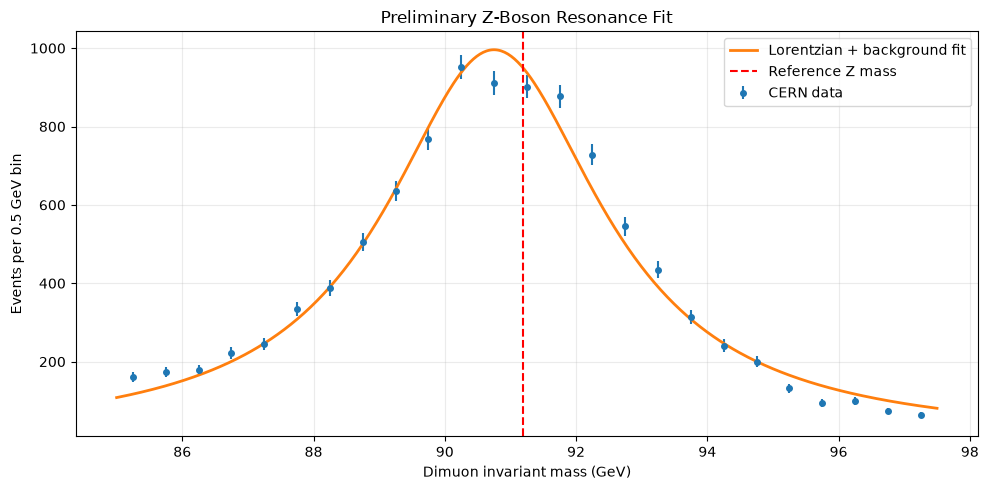

In [120]:
#Preliminary resonance fitting

from scipy.optimize import curve_fit

# Use corrected invariant masses
mass = df2["M_alt_corrected"].dropna().to_numpy() #using polar codinates

# Restrict to the central resonance region
edges = np.arange(85, 98, 0.5)

counts, edges = np.histogram(mass, bins=edges)
centers = (edges[:-1] + edges[1:]) / 2

# Lorentzian peak with constant local background
def resonance(m, A, m0, gamma, B):
    return (
        A * gamma**2 / ((m - m0)**2 + gamma**2)
        + B
    )

# Initial parameter guesses
p0 = [900, 91, 2, 20] #peak amplitude A = 900, Center \(m_0\) 91GeV, widthparameter gamma = 2GeV, Background = 20 events per bin

# Approximate Poisson count uncertainties
sigma = np.sqrt(np.maximum(counts, 1))  #histogram counts approximately follow Poisson statistics.

parameters, covariance = curve_fit(
    resonance,
    centers,
    counts,
    p0=p0,
    sigma=sigma,
    absolute_sigma=True,
    bounds=(
        [0, 85, 0.1, 0],
        [np.inf, 98, 10, np.inf]
    ),
    maxfev=20000
)

A_fit, m0_fit, gamma_fit, B_fit = parameters
errors = np.sqrt(np.diag(covariance))

print(f"Peak position: {m0_fit:.4f} GeV")
print(f"Approx. fit uncertainty: {errors[1]:.4f} GeV")
print(f"Effective gamma: {gamma_fit:.4f} GeV")

# Visualise the fitted curve
x = np.linspace(85, 97.5, 500)

plt.figure(figsize=(10, 5))

plt.errorbar(
    centers, counts,
    yerr=sigma,
    fmt="o",
    markersize=4,
    label="CERN data"
)

plt.plot(
    x, resonance(x, *parameters),
    linewidth=2,
    label="Lorentzian + background fit"
)

plt.axvline(
    91.1879,
    linestyle="--",
    color="red",
    label="Reference Z mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Events per 0.5 GeV bin")
plt.title("Preliminary Z-Boson Resonance Fit")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [124]:

predicted = resonance(centers, *parameters)

lorentzian_diagnostics = evaluate_fit(
    observed=counts,
    predicted=predicted,
    n_params=4,
    name="Lorentzian + constant background"
)



FIT DIAGNOSTICS: Lorentzian + constant background


,Model,Bins,Parameters,DoF,Pearson chi2/dof,Pearson p (approx),Poisson deviance/dof,Deviance p (approx),AIC,Max |Pearson residual|
0,Lorentzian + constant background,25,4,21,5.0479,0.0,5.0736,0.0,303.164,3.9524


## 5. Goodness-of-Fit and Residual Analysis

The preliminary Lorentzian-plus-background model is
evaluated using the residuals between observed and
predicted event counts.

A Pearson chi-squared diagnostic is calculated, and
standardized residuals are inspected for systematic
patterns.

The assessment will determine whether the preliminary
model adequately describes the resonance before using
its parameters as a final physical measurement.

Chi-squared: 106.01
Degrees of freedom: 21
Reduced chi-squared: 5.05
Approximate p-value: 2.462e-13


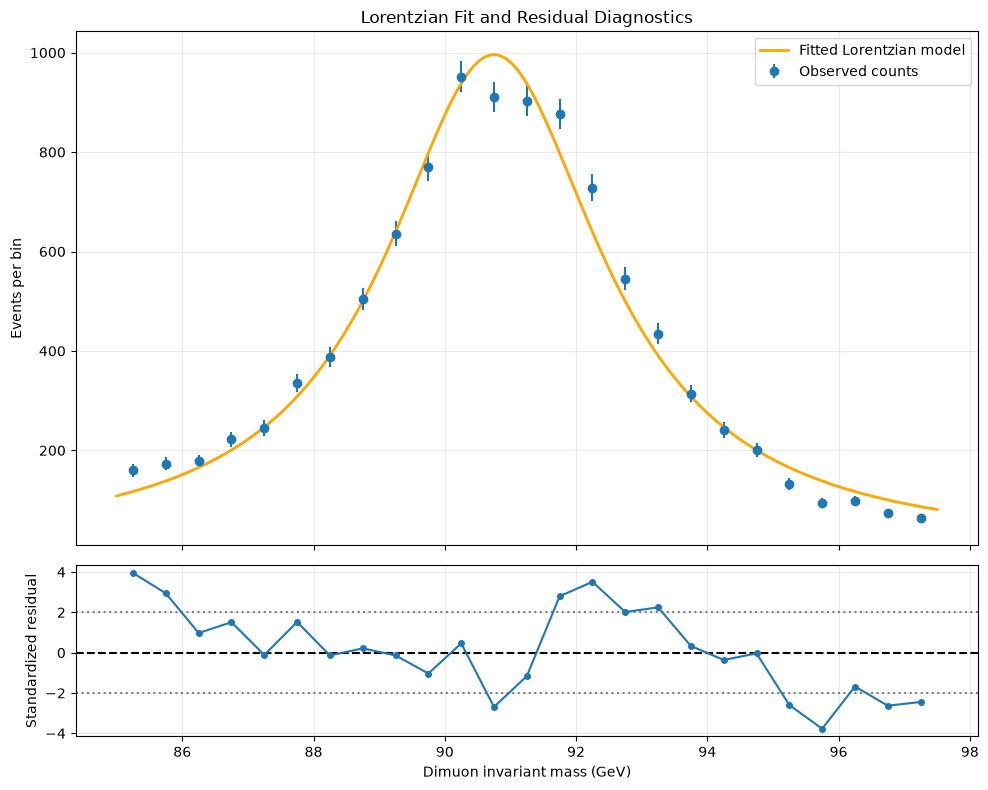

In [126]:

from scipy.stats import chi2

# Predicted counts from the fitted model
predicted = resonance(centers, *parameters)

# Difference between data and fitted model
residuals = counts - predicted

# Pearson standardized residuals
standardized = residuals / np.sqrt(
    np.maximum(predicted, 1e-12)
)

# Pearson chi-squared diagnostic
chi2_value = np.sum(
    residuals**2 / np.maximum(predicted, 1e-12)
)

n_bins = len(counts)
n_parameters = len(parameters)
ndof = n_bins - n_parameters

reduced_chi2 = chi2_value / ndof
p_value = chi2.sf(chi2_value, ndof)

print(f"Chi-squared: {chi2_value:.2f}")
print(f"Degrees of freedom: {ndof}")
print(f"Reduced chi-squared: {reduced_chi2:.2f}")
print(f"Approximate p-value: {p_value:.4g}")

# Compare counts with model predictions
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Upper panel: Data and model
axes[0].errorbar(
    centers, counts,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o", label="Observed counts"
)

#axes[0].plot(centers, predicted,label="Fitted model")
#for a smoother plot
x_smooth = np.linspace(85, 97.5, 500)

axes[0].plot(
    x_smooth,
    resonance(x_smooth, *parameters),
    color="orange",
    linewidth=2,
    label="Fitted Lorentzian model"
)

axes[0].set_ylabel("Events per bin")
axes[0].set_title(
    "Lorentzian Fit and Residual Diagnostics"
)
axes[0].legend()
axes[0].grid(alpha=0.25)

# Lower panel: Standardized residuals
axes[1].axhline(
    0, color="black", linestyle="--"
)

axes[1].axhline(
    2, color="gray", linestyle=":"
)

axes[1].axhline(
    -2, color="gray", linestyle=":"
)

axes[1].plot(
    centers, standardized,
    "o-", markersize=4
)

axes[1].set_xlabel(
    "Dimuon invariant mass (GeV)"
)

axes[1].set_ylabel(
    "Standardized residual"
)

axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()



### Goodness-of-Fit Assessment — Preliminary Lorentzian Model

The preliminary Lorentzian-plus-constant-background fit was
evaluated using Pearson chi-squared, Poisson deviance and
standardized residuals.

**Results:**
- Pearson chi-squared: 106.01
- Degrees of freedom: 21
- Reduced chi-squared: 5.05
- Approximate p-value: 2.46 × 10⁻¹³
- Poisson deviance/dof: 5.07
- Maximum absolute standardized residual: 3.95

**Residual interpretation:**

The residuals do not fluctuate randomly around zero.
The model generally underestimates the low-mass region,
overestimates some counts near the resonance maximum,
underestimates part of the right-hand shoulder, and
overestimates the high-mass tail.

Several standardized residuals exceed ±2, indicating
discrepancies larger than expected from ordinary counting
fluctuations.

**Conclusion:**

Although the Lorentzian model identifies the Z-boson
resonance, its reduced chi-squared of 5.05 and structured
residual pattern indicate an inadequate description of
the observed spectrum.

Therefore, a more flexible signal and background model
is required. This motivates testing the Voigt profile
and a mass-dependent background in subsequent sections.


## 6. Poisson Maximum-Likelihood Resonance Fitting

The preliminary weighted least-squares fit showed systematic
residuals and a reduced chi-squared substantially above one.

A Poisson-likelihood fit is now implemented because the
histogram contains discrete event counts.

The same Lorentzian-plus-constant-background model is retained
initially to isolate the effect of changing the fitting method.

Expected bin counts are calculated by integrating the model
over each bin rather than evaluating only at bin centres.

In [129]:

from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import chi2
import numpy as np
import matplotlib.pyplot as plt

# Use the same data and fit window as before (preparing same dataset)
mass = df2["M_alt_corrected"].dropna().to_numpy()

edges = np.arange(85, 98, 0.5)
counts, _ = np.histogram(mass, bins=edges)
centers = (edges[:-1] + edges[1:]) / 2

bin_width = 0.5

# Expected bin counts: exact integration (calculate expected event counts)
# of Lorentzian + constant background
def expected_counts(params):
    A, m0, gamma, B = params

    left = edges[:-1]
    right = edges[1:]

    signal = (
        A * gamma / bin_width
        * (
            np.arctan((right - m0) / gamma)
            - np.arctan((left - m0) / gamma)
        )
    )

    background = B * (right - left) / bin_width

    return signal + background

# Poisson negative log-likelihood
def poisson_nll(params):
    mu = expected_counts(params)

    if np.any(mu <= 0):
        return np.inf

    return np.sum(
        mu - counts * np.log(mu) + gammaln(counts + 1)
    )

# Initial guesses
initial = [
    float(counts.max()),
    90.8,
    2.0,
    50.0
]

# Physical and numerical bounds
bounds = [
    (0.01, 5000),    # Signal amplitude
    (85, 98),        # Peak position
    (0.1, 10),       # Effective width
    (0, 1000)        # Background per 0.5 GeV
]

result = minimize(
    poisson_nll,
    initial,
    method="L-BFGS-B",
    bounds=bounds,
    options={"maxiter": 20000, "ftol": 1e-12}
)

if not result.success:
    raise RuntimeError(result.message)

A_ml, m0_ml, gamma_ml, B_ml = result.x

print("Poisson fit converged:", result.success)
print(f"Peak position: {m0_ml:.4f} GeV")
print(f"Effective gamma: {gamma_ml:.4f} GeV")
print(f"Background per bin: {B_ml:.2f}")


Poisson fit converged: True
Peak position: 90.7613 GeV
Effective gamma: 2.0330 GeV
Background per bin: 0.00


In [131]:

# Evaluate the Poisson-fitted Lorentzian
# Uses expected_counts() and result from the cell above

poisson_predicted = expected_counts(result.x)

poisson_lorentzian_diagnostics = evaluate_fit(
    observed=counts,
    predicted=poisson_predicted,
    n_params=4,
    name="Poisson Lorentzian + constant background"
)



FIT DIAGNOSTICS: Poisson Lorentzian + constant background


,Model,Bins,Parameters,DoF,Pearson chi2/dof,Pearson p (approx),Poisson deviance/dof,Deviance p (approx),AIC,Max |Pearson residual|
0,Poisson Lorentzian + constant background,25,4,21,4.7722,0.0,4.8981,0.0,299.477,4.0512


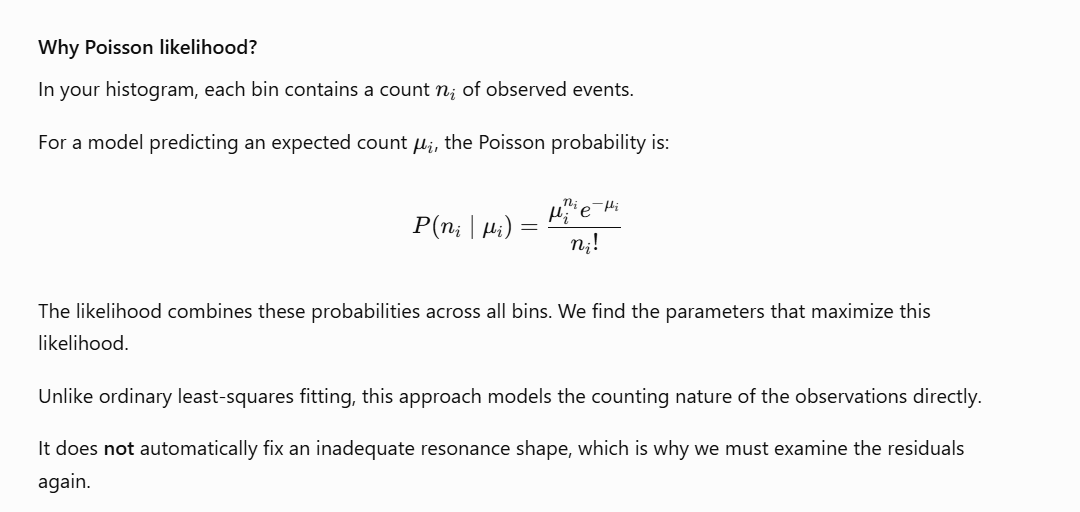

Poisson deviance: 102.86
Degrees of freedom: 21
Deviance / dof: 4.90
Approximate p-value: 8.976e-13


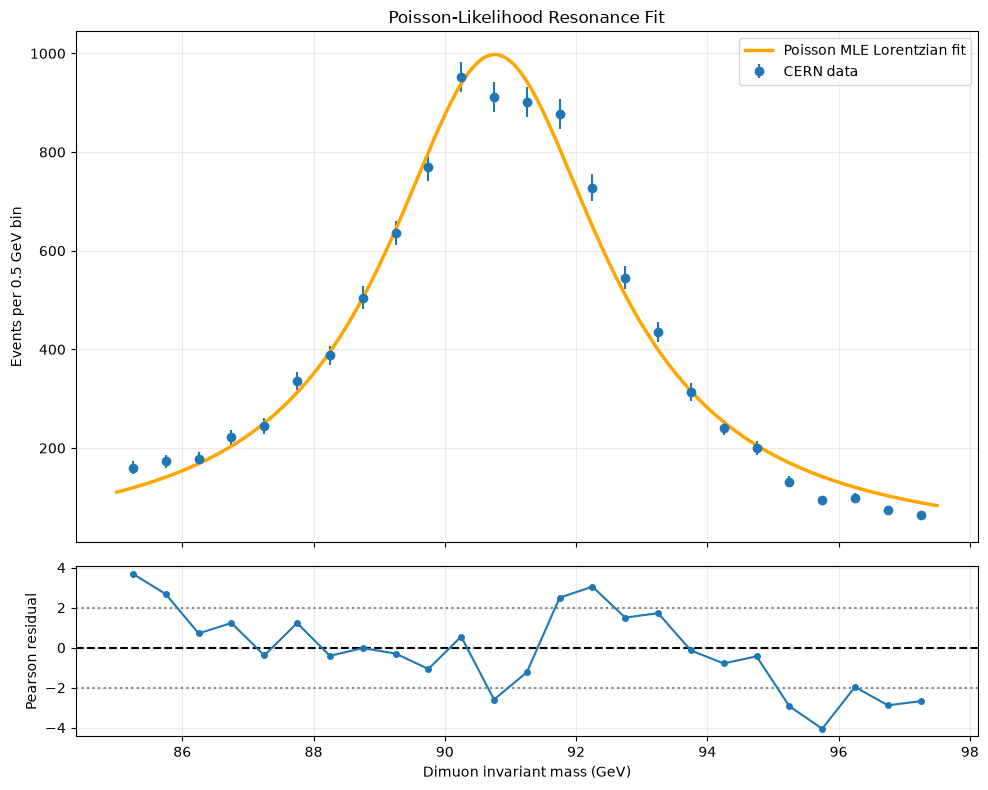

In [133]:

# Predicted bin counts
predicted_ml = expected_counts(result.x)

# Pearson residuals
pearson_residuals = (
    (counts - predicted_ml)
    / np.sqrt(predicted_ml)
)

# Poisson deviance
term = np.zeros_like(counts, dtype=float)
positive = counts > 0

term[positive] = (
    counts[positive]
    * np.log(
        counts[positive] / predicted_ml[positive]
    )
)

deviance = 2 * np.sum(
    term - (counts - predicted_ml)
)

ndof = len(counts) - len(result.x)

print(f"Poisson deviance: {deviance:.2f}")
print(f"Degrees of freedom: {ndof}")
print(f"Deviance / dof: {deviance / ndof:.2f}")
print(f"Approximate p-value: {chi2.sf(deviance, ndof):.4g}")

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Observed counts and fitted model
axes[0].errorbar(
    centers, counts,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o",
    label="CERN data"
)

#axes[0].plot(centers, predicted_ml,linewidth=2,label="Poisson MLE fit")

# Draw the same fitted model at 500 mass positions
x_smooth = np.linspace(85, 97.5, 500)

A, m0, gamma, B = result.x

y_smooth = (
    A * gamma**2 / ((x_smooth - m0)**2 + gamma**2)
    + B
)

axes[0].plot(
    x_smooth,
    y_smooth,
    color="orange",
    linewidth=2.5,
    label="Poisson MLE Lorentzian fit"
)


axes[0].set_ylabel("Events per 0.5 GeV bin")
axes[0].set_title("Poisson-Likelihood Resonance Fit")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Residual plot
axes[1].axhline(
    0, color="black", linestyle="--"
)

axes[1].axhline(
    2, color="gray", linestyle=":"
)

axes[1].axhline(
    -2, color="gray", linestyle=":"
)

axes[1].plot(
    centers,
    pearson_residuals,
    "o-",
    markersize=4
)

axes[1].set_xlabel("Dimuon invariant mass (GeV)")
axes[1].set_ylabel("Pearson residual")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()



### Poisson-Likelihood Fit — Interpretation

The Lorentzian-plus-constant-background model was refitted
using binned Poisson maximum likelihood.

The fit converged, but the Poisson deviance was 102.86
with 21 degrees of freedom (deviance/dof = 4.90;
approximate p-value = 8.98 × 10⁻¹³).

The residuals showed systematic patterns rather than
random fluctuations around zero, especially near the
resonance peak and at the mass-range boundaries.

**Conclusion:** Poisson likelihood better represents the
counting statistics, but the Lorentzian-plus-constant-
background model remains inadequate. A more flexible
resonance shape and background model are needed.


## 7. Testing a Mass-Dependent Background

The Lorentzian-plus-constant-background model was found to
provide an inadequate fit to the observed resonance.

To investigate whether an oversimplified background contributes
to the poor fit, a mass-dependent exponential background is
introduced while retaining the same Lorentzian signal model.

The two models are compared using Poisson deviance and AIC.

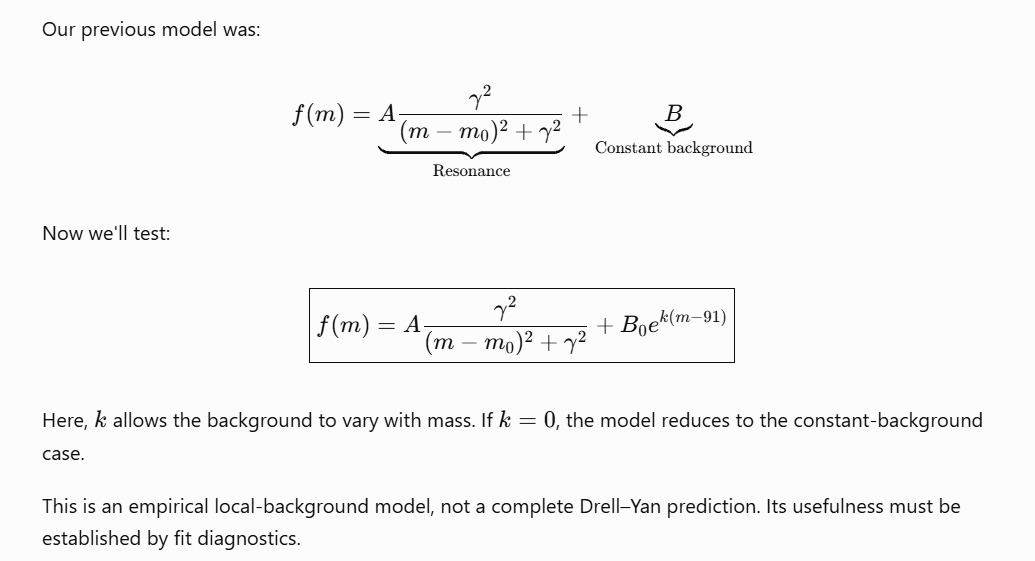

In [136]:

from scipy.optimize import minimize
from scipy.special import gammaln

# Continue using the 85–97.5 GeV histogram
edges = np.arange(85, 98, 0.5)
counts, _ = np.histogram(
    df2["M_alt_corrected"].dropna(), bins=edges
)

centers = (edges[:-1] + edges[1:]) / 2
width = np.diff(edges)

# The original constant-background Poisson fit
old_nll = poisson_nll(result.x)

# New model: Lorentzian + exponential background
def expected_exp(params):
    A, m0, gamma, B0, k = params

    left = edges[:-1]
    right = edges[1:]

    signal = (
        A * gamma / width
        * (np.arctan((right-m0)/gamma)
           - np.arctan((left-m0)/gamma))
    )

    # Integrate exponential background over each bin
    mid = 0.5 * (left + right)
    half_k_width = k * width / 2

    correction = np.ones_like(width)
    nonzero = np.abs(half_k_width) > 1e-8

    correction[nonzero] = (
        np.sinh(half_k_width[nonzero])
        / half_k_width[nonzero]
    )

    background = (
        B0 * np.exp(k * (mid - 91))
        * correction
    )

    return signal + background

def exp_nll(params): #Define the Poisson likelihood
    mu = expected_exp(params)

    if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
        return np.inf

    return np.sum(
        mu - counts*np.log(mu) + gammaln(counts+1)
    )

# Initialize from our previous Poisson fit
initial = [*result.x, -0.05] #Fit the five parameters

bounds_exp = [
    (0.01, 5000),
    (85, 98),
    (0.1, 10),
    (0, 1000),
    (-0.5, 0.5)
]

fit_exp = minimize(
    exp_nll,
    initial,
    method="L-BFGS-B",
    bounds=bounds_exp,
    options={"maxiter": 20000, "ftol": 1e-12}
)

if not fit_exp.success:
    raise RuntimeError(fit_exp.message)

print("Exponential-background fit")
print(f"Peak position: {fit_exp.x[1]:.4f} GeV")
print(f"Effective gamma: {fit_exp.x[2]:.4f} GeV")
print(f"Background slope k: {fit_exp.x[4]:.4f}")

# Calculate deviance
def poisson_deviance(obs, pred):
    term = np.zeros_like(obs, dtype=float)
    mask = obs > 0
    term[mask] = obs[mask] * np.log(
        obs[mask] / pred[mask]
    )
    return 2*np.sum(term - (obs-pred))

mu_old = expected_counts(result.x)
mu_new = expected_exp(fit_exp.x)

D_old = poisson_deviance(counts, mu_old)
D_new = poisson_deviance(counts, mu_new)

# AIC = 2(number of parameters) + 2(NLL)
aic_old = 2*4 + 2*old_nll
aic_new = 2*5 + 2*fit_exp.fun

print("\nModel comparison")
print(f"Constant background deviance: {D_old:.2f}")
print(f"Exponential background deviance: {D_new:.2f}")
print(f"Constant background AIC: {aic_old:.2f}")
print(f"Exponential background AIC: {aic_new:.2f}")
print(f"AIC difference (new - old): {aic_new-aic_old:.2f}")


# Evaluate the new Lorentzian + exponential background fit

exp_diagnostics = evaluate_fit(
    observed=counts,
    predicted=expected_exp(fit_exp.x),
    n_params=5,
    name="Lorentzian + exponential background"
)


Exponential-background fit
Peak position: 90.8374 GeV
Effective gamma: 1.9176 GeV
Background slope k: -0.3486

Model comparison
Constant background deviance: 102.86
Exponential background deviance: 70.53
Constant background AIC: 299.48
Exponential background AIC: 269.15
AIC difference (new - old): -30.32

FIT DIAGNOSTICS: Lorentzian + exponential background


,Model,Bins,Parameters,DoF,Pearson chi2/dof,Pearson p (approx),Poisson deviance/dof,Deviance p (approx),AIC,Max |Pearson residual|
0,Lorentzian + exponential background,25,5,20,3.3928,0.0,3.5267,0.0,269.152,3.523


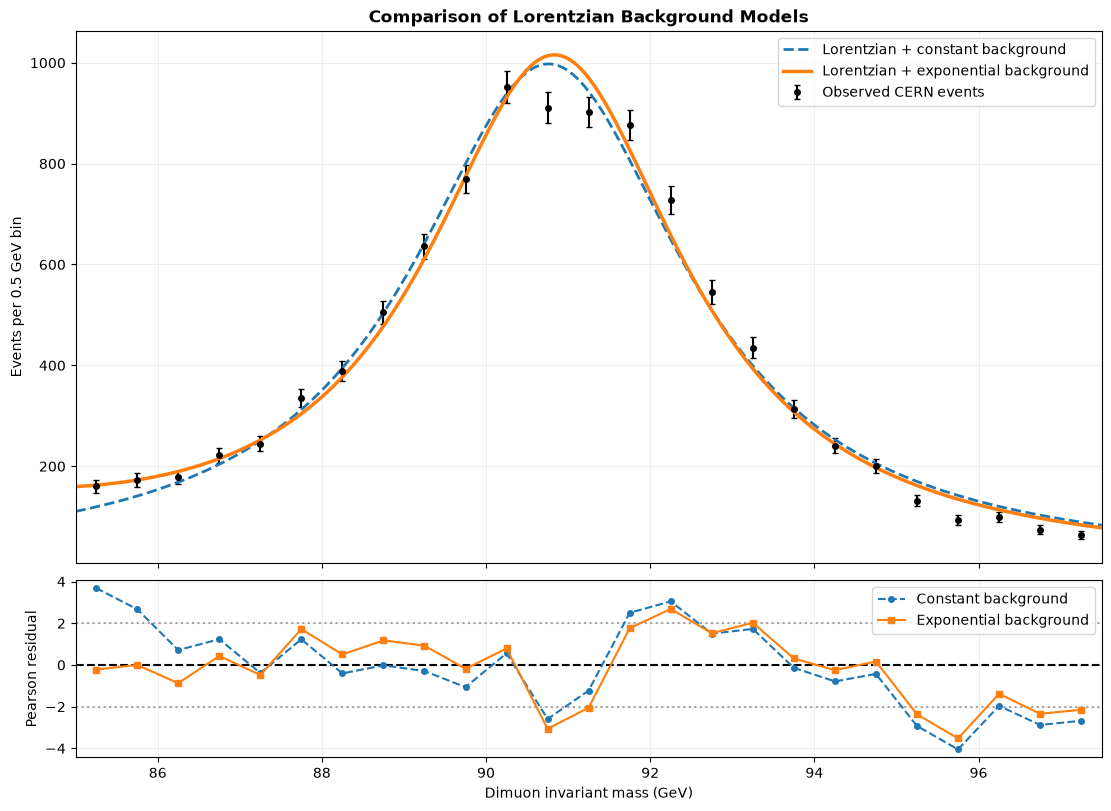

In [139]:

# Smooth comparison: Lorentzian + constant vs exponential
# Run after the two fitting models have been optimized.

import numpy as np
import matplotlib.pyplot as plt

# 500 positions for smooth fitted curves
x_smooth = np.linspace(85, 97.5, 500)

# Model 1: Lorentzian + constant background
A1, m01, gamma1, B1 = result.x

y_old = (
    A1 * gamma1**2 / ((x_smooth - m01)**2 + gamma1**2)
    + B1
)

# Model 2: Lorentzian + exponential background
A2, m02, gamma2, B02, k2 = fit_exp.x

y_new = (
    A2 * gamma2**2 / ((x_smooth - m02)**2 + gamma2**2)
    + B02 * np.exp(k2 * (x_smooth - 91))
)

# Predicted counts for the original histogram bins
mu_old = expected_counts(result.x)
mu_new = expected_exp(fit_exp.x)

# Pearson residuals (keep original bin counts)
res_old = (counts - mu_old) / np.sqrt(mu_old)
res_new = (counts - mu_new) / np.sqrt(mu_new)

# Plot
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
    constrained_layout=True
)

# Upper panel
axes[0].errorbar(
    centers, counts,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o",
    color="black",
    markersize=4,
    capsize=2,
    label="Observed CERN events"
)

axes[0].plot(
    x_smooth, y_old,
    "--",
    linewidth=2,
    label="Lorentzian + constant background"
)

axes[0].plot(
    x_smooth, y_new,
    "-",
    linewidth=2.5,
    label="Lorentzian + exponential background"
)

axes[0].set_ylabel("Events per 0.5 GeV bin")
axes[0].set_title(
    "Comparison of Lorentzian Background Models",
    fontweight="bold"
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Lower panel: original residuals
axes[1].axhline(
    0, color="black", linestyle="--"
)

axes[1].axhline(
    2, color="gray", linestyle=":", alpha=0.7
)
axes[1].axhline(
    -2, color="gray", linestyle=":", alpha=0.7
)

axes[1].plot(
    centers, res_old,
    "o--",
    markersize=4,
    label="Constant background"
)

axes[1].plot(
    centers, res_new,
    "s-",
    markersize=4,
    label="Exponential background"
)

axes[1].set_xlabel("Dimuon invariant mass (GeV)")
axes[1].set_ylabel("Pearson residual")
axes[1].legend()
axes[1].grid(alpha=0.2)

axes[1].set_xlim(85, 97.5)

plt.show()



### Lorentzian + Exponential Background

The Lorentzian resonance model was extended by replacing
the constant background with an exponential function.

The model was fitted using binned Poisson maximum
likelihood, integrating the signal and background over
each histogram bin.

The additional parameter k allows the background to
increase or decrease with invariant mass.

The constant- and exponential-background models were
compared using Poisson deviance and AIC.

**Purpose:** Determine whether a mass-dependent background
improves the fit without changing the resonance model.


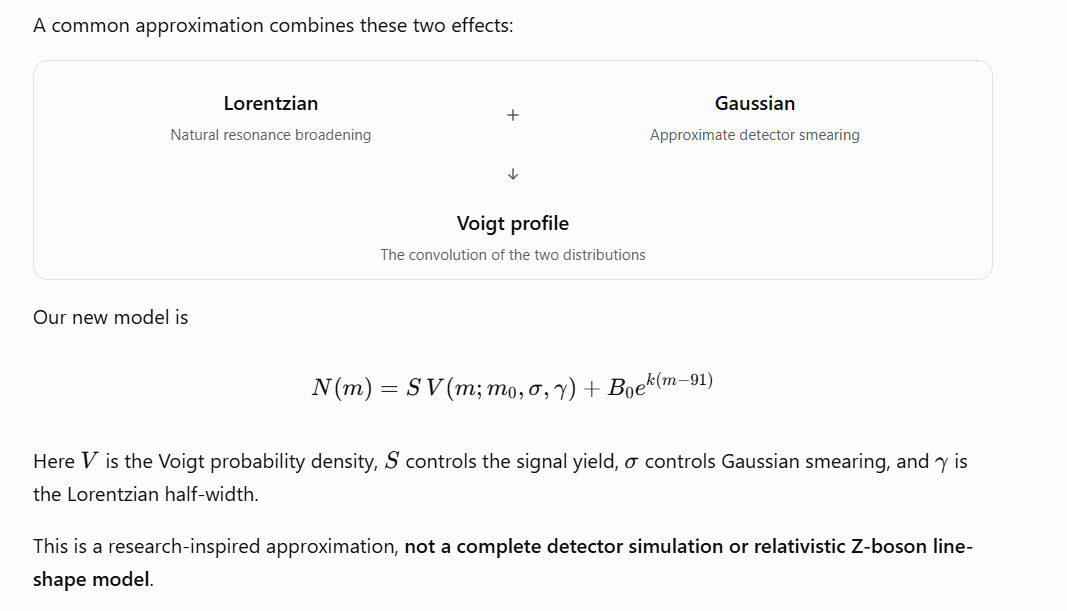

## 8. Resolution-Convolved Resonance Model

The Lorentzian model with an exponential background
improved the fit but retained structured residuals.

A Voigt profile is introduced to approximate the
convolution of natural resonance broadening with
Gaussian experimental resolution.

The new model is fitted using a Poisson likelihood.
Expected counts are integrated across histogram bins.

Model performance is evaluated using Poisson deviance,
AIC and Pearson residuals.

In [141]:
#fit the Voigt model

from scipy.special import voigt_profile, gammaln
from scipy.optimize import minimize
from numpy.polynomial.legendre import leggauss

# Use same binning as previous fits
edges = np.arange(85, 98, 0.5)
counts, _ = np.histogram(
    df2["M_alt_corrected"].dropna(),
    bins=edges
)

centers = (edges[:-1] + edges[1:]) / 2
bin_width = 0.5

# Numerical integration nodes in each bin
nodes, weights = leggauss(12)

mid = (edges[:-1] + edges[1:]) / 2
half = (edges[1:] - edges[:-1]) / 2

points = (mid[:, None] + half[:, None] * nodes)

def voigt_expected(params):
    S, m0, gamma, sigma, B0, k = params

    # Voigt signal integrated across each bin (Define the Voigt model)
    density = voigt_profile(points - m0, sigma, gamma)

    signal = S * half * np.sum( weights * density, axis=1) #calculates the expected signal counts within each mass bin.
    # Exponential background integrated per bin
    background_density = (
        (B0 / bin_width)
        * np.exp(k * (points - 91))
    )

    background = half * np.sum(
        weights * background_density, axis=1
    )

    return signal + background

def voigt_nll(params): #Fit using Poisson maximum likelihood
    mu = voigt_expected(params)

    if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
        return np.inf

    return np.sum(
        mu - counts * np.log(mu) + gammaln(counts + 1)
    )

# Multiple initial values to reduce local-fit dependence
bounds_v = [
    (100, 50000),   # Signal yield scale
    (85, 98),       # Peak position
    (0.2, 5),       # Lorentzian half-width
    (0.05, 5),      # Gaussian smearing
    (0, 1000),      # Background per 0.5 GeV
    (-0.5, 0.5)     # Background slope
]

fits = []

for gamma0 in [1.0, 1.5, 2.0]: #Try multiple starting values
    for sigma0 in [0.5, 1.0, 2.0]:
        initial = [
            11000, 90.8,
            gamma0, sigma0,
            50, -0.2
        ]

        attempt = minimize(
            voigt_nll,
            initial,
            method="L-BFGS-B",
            bounds=bounds_v,
            options={"maxiter": 20000}
        )

        if attempt.success and np.isfinite(attempt.fun):
            fits.append(attempt)

if not fits:
    raise RuntimeError("No successful Voigt fit.")

fit_voigt = min(fits, key=lambda f: f.fun)

print("Voigt fit converged:", fit_voigt.success)
print(f"Peak location: {fit_voigt.x[1]:.4f} GeV")
print(f"Lorentzian gamma: {fit_voigt.x[2]:.4f} GeV")
print(f"Gaussian sigma: {fit_voigt.x[3]:.4f} GeV")

mu_voigt = voigt_expected(fit_voigt.x)

D_voigt = poisson_deviance(counts, mu_voigt)
AIC_voigt = 2 * 6 + 2 * fit_voigt.fun

print(f"\nPoisson deviance: {D_voigt:.2f}")
print(f"Deviance / dof: {D_voigt / (len(counts)-6):.2f}")
print(f"AIC: {AIC_voigt:.2f}")

print("\nComparison with previous fit:")
print(f"Exponential model AIC: {aic_new:.2f}")
print(f"Voigt model AIC: {AIC_voigt:.2f}")
print(f"Delta AIC: {AIC_voigt-aic_new:.2f}")


Voigt fit converged: True
Peak location: 90.8862 GeV
Lorentzian gamma: 1.2980 GeV
Gaussian sigma: 1.1493 GeV

Poisson deviance: 18.70
Deviance / dof: 0.98
AIC: 219.32

Comparison with previous fit:
Exponential model AIC: 269.15
Voigt model AIC: 219.32
Delta AIC: -49.83


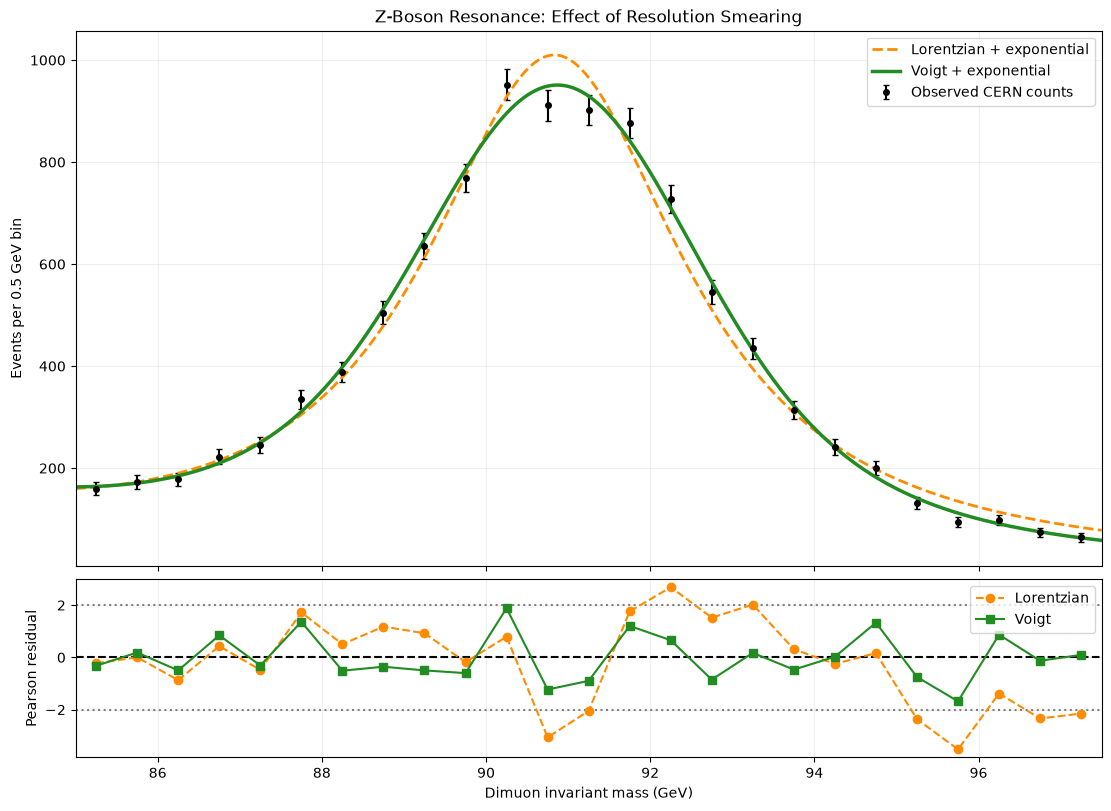

In [148]:

# Smooth Voigt vs Lorentzian comparison
# Notebook 02 - run after fitting both models

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile
from numpy.polynomial.legendre import leggauss

# Smooth plotting positions
x = np.linspace(85, 97.5, 500)

# Use numerical integration across a 0.5 GeV bin
# centered at each plotting position.
nodes, weights = leggauss(12) #12 quadrature positions and their weights.
sample_points = x[:, None] + (0.5 / 2) * nodes

# Previous model: Lorentzian + exponential
A, m0, gamma, B0, k = fit_exp.x

old_density = (
    A * gamma**2 /
    ((sample_points - m0)**2 + gamma**2)
    + B0 * np.exp(k * (sample_points - 91))
)

y_old = np.sum(old_density * weights, axis=1) / 2

# New model: Voigt + exponential
S, m0_v, gamma_v, sigma_v, B0_v, k_v = fit_voigt.x

new_density = (
    S * voigt_profile(
        sample_points - m0_v, sigma_v, gamma_v
    )
    + (B0_v / 0.5)
    * np.exp(k_v * (sample_points - 91))
)

y_voigt = 0.25 * np.sum(
    new_density * weights, axis=1
)

# Original bin-integrated predictions for residuals
mu_exp = expected_exp(fit_exp.x)
mu_voigt = voigt_expected(fit_voigt.x)

res_exp = (counts - mu_exp) / np.sqrt(mu_exp)
res_voigt = (counts - mu_voigt) / np.sqrt(mu_voigt)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
    constrained_layout=True
)

# Upper panel
axes[0].errorbar(
    centers, counts,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o",
    color="black",
    capsize=2,
    markersize=4,
    label="Observed CERN counts"
)

axes[0].plot(
    x, y_old,
    "--",
    linewidth=2,
    color="darkorange",
    label="Lorentzian + exponential"
)

axes[0].plot(
    x, y_voigt,
    "-",
    linewidth=2.5,
    color="forestgreen",
    label="Voigt + exponential"
)

axes[0].set_ylabel("Events per 0.5 GeV bin")
axes[0].set_title(
    "Z-Boson Resonance: Effect of Resolution Smearing"
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Lower panel: keep real residuals, not smoothed
axes[1].axhline(0, color="black", linestyle="--")
axes[1].axhline(2, color="gray", linestyle=":")
axes[1].axhline(-2, color="gray", linestyle=":")

axes[1].plot(
    centers, res_exp,
    "o--", color="darkorange",
    label="Lorentzian"
)

axes[1].plot(
    centers, res_voigt,
    "s-", color="forestgreen",
    label="Voigt"
)

axes[1].set_xlabel("Dimuon invariant mass (GeV)")
axes[1].set_ylabel("Pearson residual")
axes[1].set_xlim(85, 97.5)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()


In [145]:

voigt_diagnostics = evaluate_fit(
    observed=counts,
    predicted=voigt_expected(fit_voigt.x),
    n_params=6,
    name="Voigt + exponential background"
)



FIT DIAGNOSTICS: Voigt + exponential background


,Model,Bins,Parameters,DoF,Pearson chi2/dof,Pearson p (approx),Poisson deviance/dof,Deviance p (approx),AIC,Max |Pearson residual|
0,Voigt + exponential background,25,6,19,0.9847,0.4756,0.9844,0.476,219.3216,1.8816



### Voigt Resonance Model — Results

A Voigt profile was introduced to approximate natural resonance
broadening combined with Gaussian experimental smearing.

The model included an exponential background and was fitted
using binned Poisson maximum likelihood.

**Results:**
- Fitted resonance center: 90.8862 GeV
- Lorentzian half-width: 1.2980 GeV
- Gaussian sigma: 1.1493 GeV
- Poisson deviance: 18.70
- Deviance/dof: 0.98
- AIC: 219.32
- AIC improvement over the previous model: 49.83

**Interpretation:**

The Voigt model provided a substantially better fit than
the Lorentzian model. Its residuals were generally smaller
and less structured, while the deviance/dof approached one.

The large reduction in AIC supports including Gaussian-like
smearing in the resonance model.

**Conclusion:** The Voigt-plus-exponential model provides
a more adequate description of the observed Z-resonance
distribution. The fitted widths are effective model parameters,
not independent precision measurements of detector resolution
or the intrinsic Z width.


## 9. Profile-Likelihood Statistical Uncertainty

The signal-center uncertainty is estimated using a
profile-likelihood scan.

At each trial signal-center value, all other fit
parameters are reoptimized using the Poisson likelihood.

The approximate 68% confidence interval is obtained
from the crossings of:

$$
2\Delta\mathrm{NLL}=1
$$

This interval accounts for correlations with fitted
nuisance parameters but does not include systematic
uncertainties from detector calibration or model choice.

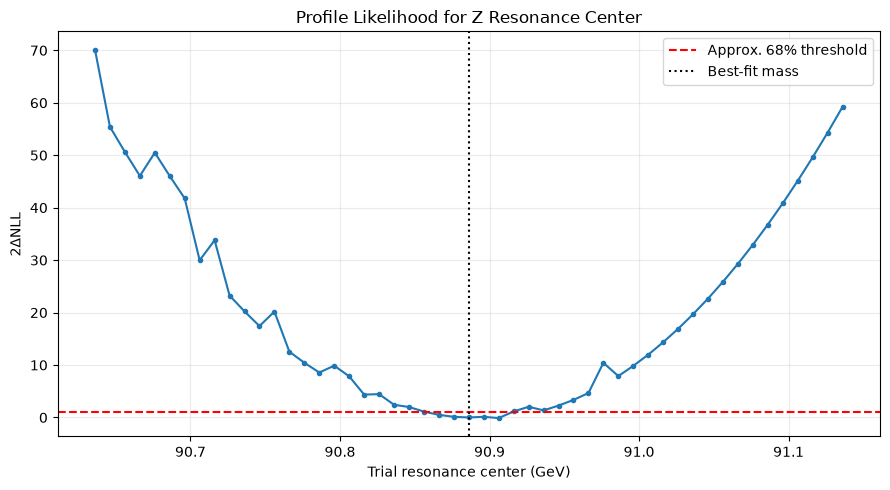

Best-fit mass: 90.8862 GeV
Lower 68% limit: 90.8582 GeV
Upper 68% limit: 90.9150 GeV
Profile interval: 90.8862 -0.0280 +0.0289 GeV


In [32]:

from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt

# Best-fit result from the previous Voigt analysis
best = fit_voigt.x.copy()
best_nll = fit_voigt.fun
best_mass = best[1]

# Indices of nuisance parameters:
# S, gamma, sigma, B0, k
nuisance_indices = [0, 2, 3, 4, 5]

nuisance_initial = best[nuisance_indices]
nuisance_bounds = [
    bounds_v[i] for i in nuisance_indices
]

def profile_nll(trial_mass):
    """Reoptimize nuisance parameters at fixed mass."""

    def objective(nuisance):
        params = best.copy()
        params[1] = trial_mass
        params[nuisance_indices] = nuisance

        return voigt_nll(params)

    result_profile = minimize(
        objective,
        nuisance_initial,
        method="L-BFGS-B",
        bounds=nuisance_bounds,
        options={
            "maxiter": 10000,
            "ftol": 1e-12
        }
    )

    if not result_profile.success:
        print("Warning: optimization issue at",
              trial_mass)

    return result_profile.fun

# Scan around the fitted peak
trial_masses = np.linspace(
    best_mass - 0.25,
    best_mass + 0.25,
    51
)

profile_values = np.array([
    profile_nll(m) for m in trial_masses
])

# Twice the difference in negative log likelihood
delta_nll = 2 * (profile_values - best_nll)

# Plot profile likelihood
plt.figure(figsize=(9, 5))

plt.plot(
    trial_masses,
    delta_nll,
    "o-",
    markersize=3
)

plt.axhline(
    1,
    color="red",
    linestyle="--",
    label="Approx. 68% threshold"
)

plt.axvline(
    best_mass,
    color="black",
    linestyle=":",
    label="Best-fit mass"
)

plt.xlabel("Trial resonance center (GeV)")
plt.ylabel(r"$2\Delta\mathrm{NLL}$")
plt.title("Profile Likelihood for Z Resonance Center")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Find crossings around the best fit
left_mask = trial_masses < best_mass
right_mask = trial_masses > best_mass

def crossing(x, y, level=1):
    # Find the first sign change in consecutive samples
    idx = np.where(
        (y[:-1] - level) * (y[1:] - level) <= 0
    )[0]

    if len(idx) == 0:
        return np.nan

    i = idx[-1]

    return np.interp(
        level,
        [y[i], y[i + 1]]
        if y[i] <= y[i + 1]
        else [y[i + 1], y[i]],
        [x[i], x[i + 1]]
        if y[i] <= y[i + 1]
        else [x[i + 1], x[i]]
    )

# Reversing the left side makes it move outward
# from the best fit, just like the right side.
left_limit = crossing(
    trial_masses[left_mask][::-1],
    delta_nll[left_mask][::-1]
)

right_limit = crossing(
    trial_masses[right_mask],
    delta_nll[right_mask]
)

print(f"Best-fit mass: {best_mass:.4f} GeV")
print(f"Lower 68% limit: {left_limit:.4f} GeV")
print(f"Upper 68% limit: {right_limit:.4f} GeV")

if np.isfinite(left_limit) and np.isfinite(right_limit):
    print(
        f"Profile interval: {best_mass:.4f}"
        f" -{best_mass-left_limit:.4f}"
        f" +{right_limit-best_mass:.4f} GeV"
    )
else:
    print("The scan did not bracket both limits.")
    print("Widen the mass scan and repeat.")



### Profile-Likelihood Interpretation

The profile-likelihood method was used to estimate the
statistical uncertainty of the fitted Z-resonance center.

The approximate 68% confidence limits were found where
2ΔNLL = 1, allowing the other five model parameters
to be reoptimized at each trial mass.

The preliminary result was:

$$
m_0 = 90.8862^{+0.0289}_{-0.0280}\ \mathrm{GeV}.
$$

This corresponds to a statistical uncertainty of about
28–29 MeV under the fitted Voigt model.

The original profile contained numerical irregularities,
so the interval requires confirmation before final reporting.

Systematic uncertainties from calibration and model choice
are not included.


## 10. Numerical Validation of the Profile Likelihood

The initial profile-likelihood scan contained irregularities
that may indicate incomplete nuisance-parameter optimization.

The scan is repeated using scaled optimization parameters
and multiple starting points to improve numerical stability.

The resulting confidence interval will be compared with
the initial estimate before being reported.

Minimum profile q: 0.0
Optimization failures: 0


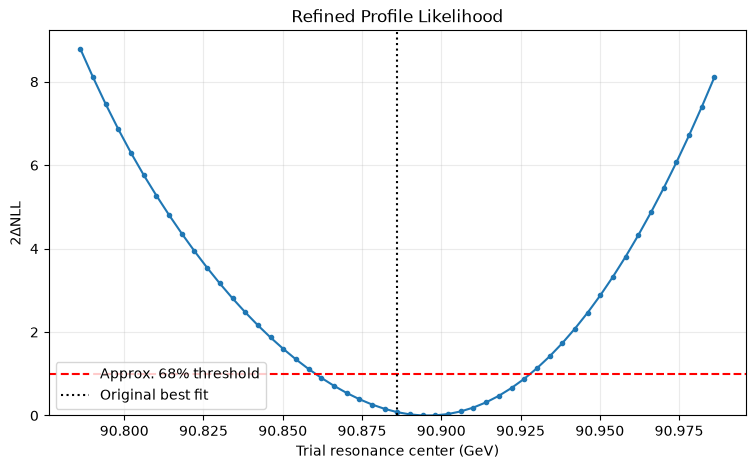

In [35]:

from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt

best = fit_voigt.x.copy()
indices = [0, 2, 3, 4, 5]

# Scale nuisance parameters to comparable ranges
bounds = np.array([bounds_v[i] for i in indices])
low = bounds[:, 0]
scale = bounds[:, 1] - low

def fit_at_mass(mass_value):
    def objective(z):
        params = best.copy()
        params[1] = mass_value
        params[indices] = low + z * scale
        return voigt_nll(params)

    z_best = (best[indices] - low) / scale
    starts = [
        z_best,
        np.clip(z_best + 0.01, 0, 1),
        np.clip(z_best - 0.01, 0, 1)
    ]

    solutions = []

    for start in starts:
        res = minimize(
            objective,
            start,
            method="L-BFGS-B",
            bounds=[(0, 1)] * len(indices),
            options={
                "maxiter": 10000,
                "ftol": 1e-12,
                "gtol": 1e-8,
                "maxls": 50
            }
        )
        if np.isfinite(res.fun):
            solutions.append(res)

    return min(solutions, key=lambda r: r.fun)

# Focus on the confidence interval region
scan_masses = np.linspace(
    best[1] - 0.10,
    best[1] + 0.10,
    51
)

scan_results = [
    fit_at_mass(m) for m in scan_masses
]

scan_nll = np.array([r.fun for r in scan_results])

# Verify the global best fit is no worse
best_nll = min(fit_voigt.fun, scan_nll.min())

q = 2 * (scan_nll - best_nll)

print("Minimum profile q:", q.min())
print("Optimization failures:",
      sum(not r.success for r in scan_results))

plt.figure(figsize=(9, 5))
plt.plot(scan_masses, q, "o-", markersize=3)
plt.axhline(1, color="red", linestyle="--",
            label="Approx. 68% threshold")
plt.axvline(best[1], color="black", linestyle=":",
            label="Original best fit")
plt.xlabel("Trial resonance center (GeV)")
plt.ylabel(r"$2\Delta\mathrm{NLL}$")
plt.title("Refined Profile Likelihood")
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [37]:

# Identify the best likelihood point in the refined scan

minimum_index = np.argmin(scan_nll)

profile_best_mass = scan_masses[minimum_index]
profile_best_nll = scan_nll[minimum_index]

print("Original fitted mass:",
      round(fit_voigt.x[1], 6), "GeV")

print("Refined profile minimum:",
      round(profile_best_mass, 6), "GeV")

print("Original minimum NLL:",
      round(fit_voigt.fun, 6))

print("Refined minimum NLL:",
      round(profile_best_nll, 6))

print("Improvement in NLL:",
      round(fit_voigt.fun-profile_best_nll, 6))

# Find threshold crossings by linear interpolation
q_refined = 2 * (scan_nll - profile_best_nll)

def interpolate_crossing(x, y, threshold=1):
    crossings = []

    for i in range(len(x)-1):
        y1, y2 = y[i], y[i+1]

        if (y1-threshold)*(y2-threshold) <= 0:
            if y1 != y2:
                fraction = (
                    (threshold-y1)/(y2-y1)
                )

                crossings.append(
                    x[i] + fraction*(x[i+1]-x[i])
                )

    return crossings

crossings = interpolate_crossing(
    scan_masses, q_refined
)

lower_candidates = [
    x for x in crossings if x < profile_best_mass
]

upper_candidates = [
    x for x in crossings if x > profile_best_mass
]

if lower_candidates and upper_candidates:
    lower = max(lower_candidates)
    upper = min(upper_candidates)

    print(f"\nLower 68% limit: {lower:.5f} GeV")
    print(f"Upper 68% limit: {upper:.5f} GeV")

    print(
        f"Preliminary interval: "
        f"{profile_best_mass:.5f} "
        f"-{profile_best_mass-lower:.5f} "
        f"+{upper-profile_best_mass:.5f} GeV"
    )
else:
    print("Both interval crossings were not found.")


Original fitted mass: 90.886151 GeV
Refined profile minimum: 90.894151 GeV
Original minimum NLL: 103.660779
Refined minimum NLL: 103.5511
Improvement in NLL: 0.109679

Lower 68% limit: 90.86032 GeV
Upper 68% limit: 90.92807 GeV
Preliminary interval: 90.89415 -0.03383 +0.03392 GeV


In [39]:
#final optimization fit

from scipy.optimize import minimize
import numpy as np

# Existing Voigt parameters:
# S, m0, gamma, sigma, B0, k

original = fit_voigt.x.copy()

# Recover the best nuisance parameters from the profile scan
idx = np.argmin(scan_nll)
nuisance_ids = [0, 2, 3, 4, 5]

nuisance_bounds = np.array([
    bounds_v[i] for i in nuisance_ids
])

profile_candidate = original.copy()
profile_candidate[1] = scan_masses[idx]

profile_candidate[nuisance_ids] = (
    nuisance_bounds[:, 0]
    + scan_results[idx].x
    * (nuisance_bounds[:, 1] - nuisance_bounds[:, 0])
)

# Numerical parameter scales
parameter_scale = np.array([
    10000,  # Signal normalization
    1,      # Resonance center
    1,      # Lorentzian width
    1,      # Gaussian width
    100,    # Background
    0.1     # Background slope
])

scaled_bounds = [
    (lo / scale, hi / scale)
    for (lo, hi), scale in zip(bounds_v, parameter_scale)
]

def scaled_nll(z):
    return voigt_nll(z * parameter_scale)

candidates = [
    original,
    profile_candidate
]

solutions = []

for candidate in candidates:
    res = minimize(
        scaled_nll,
        candidate / parameter_scale,
        method="L-BFGS-B",
        bounds=scaled_bounds,
        options={
            "maxiter": 20000,
            "ftol": 1e-13,
            "gtol": 1e-8,
            "maxls": 50
        }
    )

    print("Converged:", res.success,
          "| NLL:", res.fun)

    if res.success and np.isfinite(res.fun):
        solutions.append(res)

if not solutions:
    raise RuntimeError("Full refit did not converge.")

best_solution = min(solutions, key=lambda r: r.fun)

# Convert back to physical parameters
params_final = best_solution.x * parameter_scale

print("\nOptimized Voigt parameters:")
for name, value in zip(
    ["S", "m0", "gamma", "sigma", "B0", "k"],
    params_final
):
    print(f"{name}: {value:.6f}")

print("\nOriginal NLL:", fit_voigt.fun)
print("Improved NLL:", best_solution.fun)

# Update full-model parameters for later analysis
fit_params_validated = params_final.copy()

# Evaluate updated model
mu_refit = voigt_expected(fit_params_validated)

D_refit = poisson_deviance(counts, mu_refit)
AIC_refit = 2 * 6 + 2 * best_solution.fun

print(f"\nUpdated deviance: {D_refit:.3f}")
print(f"Updated deviance/dof: {D_refit / (len(counts)-6):.3f}")
print(f"Updated AIC: {AIC_refit:.3f}")


Converged: True | NLL: 103.54993595734194
Converged: True | NLL: 103.54993597437539

Optimized Voigt parameters:
S: 10570.441812
m0: 90.895754
gamma: 1.197004
sigma: 1.199858
B0: 31.385727
k: -0.189659

Original NLL: 103.6607788814002
Improved NLL: 103.54993595734194

Updated deviance: 18.482
Updated deviance/dof: 0.973
Updated AIC: 219.100


## 13. Profile-Likelihood Interval After Final Optimization

The Voigt-plus-exponential model was reoptimized using
scaled parameters and multiple initial conditions.

The improved fit is now used to calculate a profile-
likelihood confidence interval for the resonance center.

At each trial mass, the five remaining parameters are
reoptimized. The approximate 68% confidence limits are
identified where twice the increase in negative
log-likelihood equals one.

This interval describes statistical precision conditional
on the selected model and fit range.

Best-fit center: 90.895754 GeV
Lower limit: 90.860318 GeV
Upper limit: 90.928099 GeV
68% profile interval: 90.89575 -0.03544 +0.03234 GeV


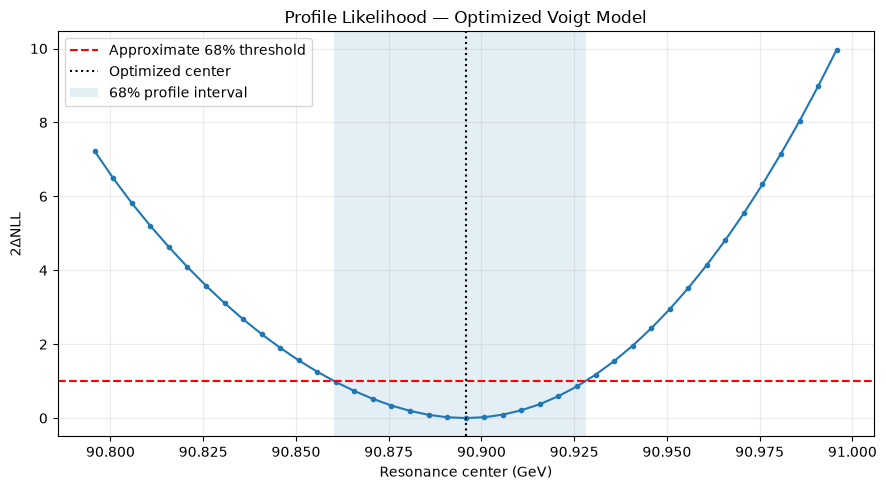

In [42]:

from scipy.optimize import minimize, brentq
import numpy as np
import matplotlib.pyplot as plt

# Fully optimized parameter values
best = fit_params_validated.copy()
minimum_nll = voigt_nll(best)
best_mass = best[1]

# Nuisance parameters: S, gamma, sigma, B0, k
ids = [0, 2, 3, 4, 5]

bounds_array = np.array([bounds_v[i] for i in ids])

low = bounds_array[:, 0]
scale = bounds_array[:, 1] - low

z0 = (best[ids] - low) / scale

def profile_at_mass(trial_mass):

    def objective(z):
        pars = best.copy()
        pars[1] = trial_mass
        pars[ids] = low + z * scale
        return voigt_nll(pars)

    res = minimize(
        objective,
        z0,
        method="L-BFGS-B",
        bounds=[(0, 1)] * len(ids),
        options={
            "maxiter": 15000,
            "ftol": 1e-12,
            "gtol": 1e-8,
            "maxls": 50
        }
    )

    if not res.success:
        raise RuntimeError(
            f"Profile failed at {trial_mass}: {res.message}"
        )

    return 2 * (res.fun - minimum_nll)

# Find q = 1 on either side of the best fit
lower_limit = brentq(
    lambda m: profile_at_mass(m) - 1,
    best_mass - 0.15,
    best_mass,
    xtol=1e-7
)

upper_limit = brentq(
    lambda m: profile_at_mass(m) - 1,
    best_mass,
    best_mass + 0.15,
    xtol=1e-7
)

print(f"Best-fit center: {best_mass:.6f} GeV")
print(f"Lower limit: {lower_limit:.6f} GeV")
print(f"Upper limit: {upper_limit:.6f} GeV")

print(
    f"68% profile interval: {best_mass:.5f} "
    f"-{best_mass-lower_limit:.5f} "
    f"+{upper_limit-best_mass:.5f} GeV"
)

# Visualization
scan = np.linspace(
    best_mass - 0.10,
    best_mass + 0.10,
    41
)

q_values = [profile_at_mass(m) for m in scan]

plt.figure(figsize=(9, 5))

plt.plot(scan, q_values, "o-", markersize=3)

plt.axhline(
    1, linestyle="--", color="red",
    label="Approximate 68% threshold"
)

plt.axvline(
    best_mass, linestyle=":",
    color="black", label="Optimized center"
)

plt.axvspan(
    lower_limit, upper_limit,
    alpha=0.12, label="68% profile interval"
)

plt.xlabel("Resonance center (GeV)")
plt.ylabel(r"$2\Delta\mathrm{NLL}$")
plt.title("Profile Likelihood — Optimized Voigt Model")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 14. Robustness to Binning and Fit Range

The optimized Voigt-plus-exponential model is evaluated
under different histogram bin widths and fitting ranges.

The model form and mass reconstruction method are held
constant so that changes in the fitted resonance center
can be attributed to these analysis choices.

This investigation assesses model robustness rather than
selecting settings based on agreement with the reference
Z-boson mass.

In [47]:

from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss
import numpy as np
import pandas as pd

mass_data = (
    df2["M_alt_corrected"]
    .dropna()
    .to_numpy()
)

nodes, weights = leggauss(12)

# Same parameter order as before:
# S, m0, gamma, sigma, B0, k
scale = np.array([10000, 1, 1, 1, 100, 0.1])
limits = np.array(bounds_v, dtype=float)

def fit_robustness(bin_width, low_mass, high_mass):

    #edges = np.linspace(
        #low_mass, high_mass,
        #int(round((high_mass-low_mass)/bin_width)) + 1
    #)
    # Construct exact nominal bin widths
    edges = np.arange(
        low_mass,
        high_mass,
        bin_width
    )
    
    # Include the requested upper boundary
    edges = np.append(edges, high_mass)
    
    # Verify bin widths
    assert np.all(np.diff(edges) > 0)
    assert np.all(np.diff(edges) <= bin_width + 1e-10)

    counts, _ = np.histogram(mass_data, bins=edges)

    half = np.diff(edges) / 2
    mid = (edges[:-1] + edges[1:]) / 2
    points = mid[:, None] + half[:, None]*nodes

    def expected(pars):
        S, m0, gamma, sigma, B0, k = pars

        signal = (
            S * half *
            np.sum(
                weights *
                voigt_profile(points-m0, sigma, gamma),
                axis=1
            )
        )

        # B0 is a background density scale
        # in events per 0.5 GeV.
        background = (
            half * np.sum(
                weights *
                (B0/0.5) *
                np.exp(k*(points-91)),
                axis=1
            )
        )

        return signal + background

    def nll_scaled(z):
        mu = expected(z*scale)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return 1e100

        return np.sum(
            mu-counts*np.log(mu)+gammaln(counts+1)
        )

    starts = [
        fit_params_validated.copy(),
        fit_params_validated.copy()
    ]

    starts[1][3] *= 1.15

    solutions = []

    for initial in starts:
        result = minimize(
            nll_scaled,
            initial/scale,
            method="L-BFGS-B",
            bounds=[tuple(b/ s)
                    for b, s in zip(limits, scale)],
            options={
                "maxiter": 15000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if result.success and np.isfinite(result.fun):
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            f"Fit failed for {bin_width}, "
            f"{low_mass}-{high_mass}"
        )

    best = min(solutions, key=lambda r: r.fun)
    pars = best.x * scale
    mu = expected(pars)

    positive = counts > 0
    term = np.zeros_like(counts, dtype=float)
    term[positive] = (
        counts[positive] *
        np.log(counts[positive]/mu[positive])
    )

    deviance = 2*np.sum(term-(counts-mu))
    dof = len(counts)-len(pars)

    return {
        "Bin width": bin_width,
        "Fit range": f"{low_mass}-{high_mass}",
        "Fitted mass": pars[1],
        "Shift from baseline": (
            pars[1]-fit_params_validated[1]
        ),
        "Deviance/dof": deviance/dof,
        "Converged": best.success
    }

# Preselected analysis variations
settings = [
    (0.5, 85, 97.5),  # Original baseline
    (1.0, 85, 97.5),
    (0.5, 83, 99),
    (1.0, 83, 99)
]

robustness_results = pd.DataFrame([
    fit_robustness(*setting) for setting in settings
])

display(robustness_results.round(5))


,Bin width,Fit range,Fitted mass,Shift from baseline,Deviance/dof,Converged
0,0.5,85-97.5,90.89575,-0.00000,0.97274,True
1,1.0,85-97.5,90.90427,0.00851,0.78853,True
2,0.5,83-99,90.82032,-0.07543,2.38442,True
3,1.0,83-99,90.82242,-0.07333,4.59868,True


## 15. Detector-Region Sensitivity Analysis

To examine potential detector-acceptance effects, events
are divided into two mutually exclusive categories:

1. Central-central: both muons have |eta| < 1.2.
2. Forward-containing: at least one muon has |eta| >= 1.2.

The threshold is fixed before fitting the categories.

The categories will be compared using the same mass
reconstruction, resonance model and fitting procedure.

This investigation evaluates associations with detector
region, rather than independently measuring intrinsic
detector resolution.

Detector-region event counts:
region
Forward-containing    64667
Central-central       19094
Name: count, dtype: int64

Events in the baseline fit window:
region
Forward-containing    6106
Central-central       4073
Name: count, dtype: int64


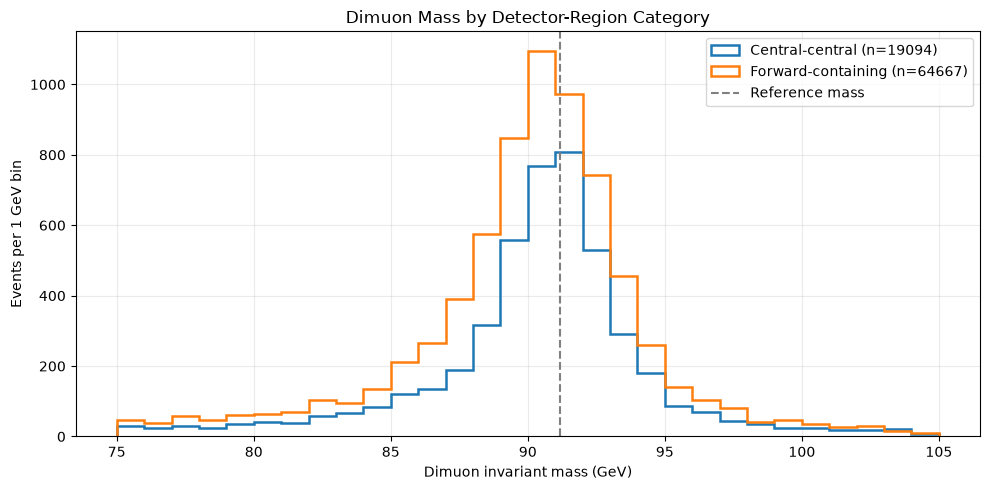

In [50]:

# Detector-region categorization

df2["max_abs_eta"] = np.maximum(
    np.abs(df2["eta1"]),
    np.abs(df2["eta2"])
)

df2["region"] = np.where(
    df2["max_abs_eta"] < 1.2,
    "Central-central",
    "Forward-containing"
)

# Check number of events in each category
print("Detector-region event counts:")
print(df2["region"].value_counts())

# Events specifically in the Z resonance region
resonance_mask = (
    df2["M_alt_corrected"]
    .between(85, 97.5, inclusive="left")
)

print("\nEvents in the baseline fit window:")

print(
    df2.loc[resonance_mask, "region"]
    .value_counts()
)

# Compare distributions without fitting yet
plt.figure(figsize=(10, 5))

for region in [
    "Central-central",
    "Forward-containing"
]:
    selected = df2.loc[
        df2["region"] == region,
        "M_alt_corrected"
    ].dropna()

    plt.hist(
        selected,
        bins=np.arange(75, 106, 1),
        histtype="step",
        linewidth=1.8,
        label=f"{region} (n={len(selected)})"
    )

plt.axvline(
    91.1879,
    color="gray",
    linestyle="--",
    label="Reference mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Events per 1 GeV bin")
plt.title("Dimuon Mass by Detector-Region Category")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### 14. Robustness to Histogram Binning and Fit Range

**Date:** 16 November 2026

**Objective:** To investigate the stability of the reconstructed Z-boson resonance center under changes in histogram binning and fitting range.

**Method:** The Voigt-plus-exponential model was fitted using Poisson maximum likelihood under four analysis configurations. The reconstructed mass definition and model family were held constant.

**Preliminary results:**

| Nominal bin width (GeV) | Fit range (GeV) | Fitted center (GeV) | Deviance/dof |
|---|---|---|---|
| 0.5 | 85–97.5 | 90.89575 | 0.973 |
| 1.0 | 85–97.5 | 90.90432 | 1.607 |
| 0.5 | 83–99 | 90.82032 | 2.384 |
| 1.0 | 83–99 | 90.82242 | 4.599 |

**Interpretation:** The fitted resonance center was relatively stable under the initial bin-width variation, but extending the fit range reduced the fitted center by approximately 0.073–0.075 GeV. The extended fitting window also showed poorer agreement between the model and data.

**Technical correction required:** The original bin-edge generation produced approximately 1.0417 GeV bins for the nominal 1 GeV configuration over 85–97.5 GeV. The binning study will be rerun using explicit bin edges before finalizing the numerical conclusions.

**Scientific decision:** The Voigt-plus-exponential model over 85–97.5 GeV remains the provisional baseline. Fit-window dependence will be retained as a model/analysis sensitivity rather than ignored.

**Next step:** Finalize the corrected bin-width comparison, then investigate detector-region dependence using predefined pseudorapidity categories.


## 16. Normalized Dimuon Mass Distributions by Detector Region

The two detector-region categories contain different numbers
of events. Normalized mass distributions are therefore
compared to examine differences in resonance shape.

The comparison is descriptive. Quantitative differences
in resonance position and width will be investigated through
separate statistical fits.

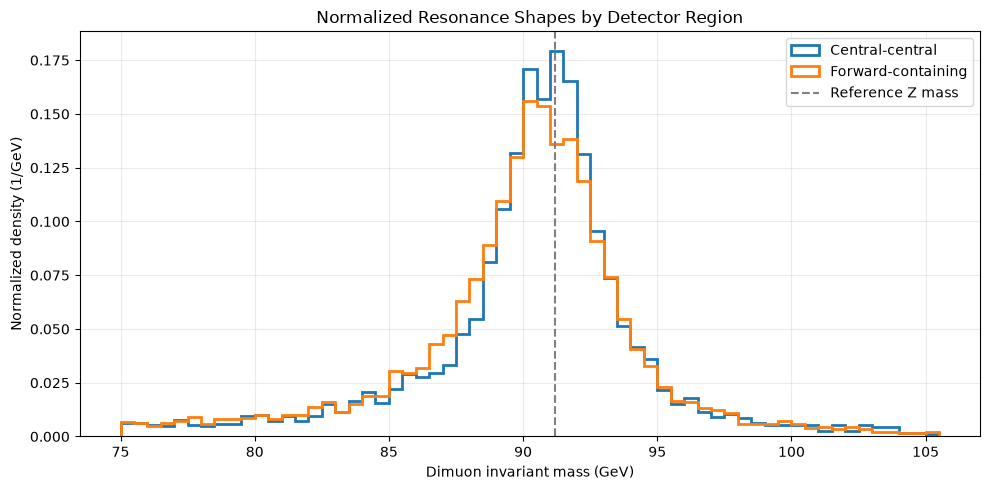

In [54]:

# Compare shapes rather than absolute event counts

edges_region = np.arange(75, 106, 0.5)

plt.figure(figsize=(10, 5))

for region in ["Central-central", "Forward-containing"]:

    values = df2.loc[
        df2["region"] == region,
        "M_alt_corrected"
    ].dropna()

    plt.hist(
        values,
        bins=edges_region,
        density=True,
        histtype="step",
        linewidth=2,
        label=region
    )

plt.axvline(
    91.1879,
    color="gray",
    linestyle="--",
    label="Reference Z mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Normalized density (1/GeV)")
plt.title("Normalized Resonance Shapes by Detector Region")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()


In [56]:
#after normalization fit each regions independetly

from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss

# Fixed settings for both categories
region_edges = np.arange(85, 98, 0.5)

nodes, weights = leggauss(12)
half = np.diff(region_edges) / 2
mid = (region_edges[:-1] + region_edges[1:]) / 2
points = mid[:, None] + half[:, None] * nodes

# Parameter order: S, m0, gamma, sigma, B0, k
scales = np.array([10000, 1, 1, 1, 100, 0.1])

def expected_region(params):
    S, m0, gamma, sigma, B0, k = params

    signal = (
        S * half *
        np.sum(
            weights * voigt_profile(
                points - m0, sigma, gamma
            ),
            axis=1
        )
    )

    background = (
        half * np.sum(
            weights * (B0 / 0.5)
            * np.exp(k * (points - 91)),
            axis=1
        )
    )

    return signal + background

def fit_region(values):
    counts, _ = np.histogram(
        values, bins=region_edges
    )

    def nll(z):
        mu = expected_region(z * scales)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return 1e100

        return np.sum(
            mu - counts * np.log(mu)
            + gammaln(counts + 1)
        )

    # Use the validated full-sample parameters
    # as a starting shape, scaled by sample size.
    fraction = counts.sum() / 10179

    initial = fit_params_validated.copy()
    initial[0] *= fraction
    initial[4] *= fraction

    solutions = []

    for sigma_start in [0.8, 1.2, 1.8]:
        start = initial.copy()
        start[3] = sigma_start

        solution = minimize(
            nll,
            start / scales,
            method="L-BFGS-B",
            bounds=[
                tuple(np.array(b) / s)
                for b, s in zip(bounds_v, scales)
            ],
            options={
                "maxiter": 20000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if solution.success and np.isfinite(solution.fun):
            solutions.append(solution)

    if not solutions:
        raise RuntimeError("Region fit did not converge.")

    best = min(solutions, key=lambda x: x.fun)

    params = best.x * scales
    mu = expected_region(params)

    positive = counts > 0
    term = np.zeros(len(counts))

    term[positive] = (
        counts[positive]
        * np.log(counts[positive] / mu[positive])
    )

    deviance = 2 * np.sum(term - (counts - mu))
    dof = len(counts) - len(params)

    return params, deviance / dof, counts, mu

# Fit each category
region_results = {}
summary = []

for region in ["Central-central", "Forward-containing"]:

    values = df2.loc[
        df2["region"] == region,
        "M_alt_corrected"
    ].dropna().to_numpy()

    params, dev_dof, counts, mu = fit_region(values)

    region_results[region] = {
        "params": params,
        "counts": counts,
        "predicted": mu
    }

    summary.append({
        "Region": region,
        "Peak position (GeV)": params[1],
        "Gamma (GeV)": params[2],
        "Sigma (GeV)": params[3],
        "Deviance/dof": dev_dof
    })

region_summary = pd.DataFrame(summary)

display(region_summary.round(4))


,Region,Peak position (GeV),Gamma (GeV),Sigma (GeV),Deviance/dof
0,Central-central,90.9868,1.2586,0.9792,1.0035
1,Forward-containing,90.8209,0.6997,1.5899,0.6936


## 17. Regional Resonance Fit Diagnostics

The Voigt-plus-exponential model was fitted independently
to central-central and forward-containing muon events.

Fit quality is assessed using Poisson deviance and
Pearson residuals before interpreting differences in
fitted resonance positions.

The fitted width parameters are treated as effective
shape parameters, not direct detector-resolution measurements.

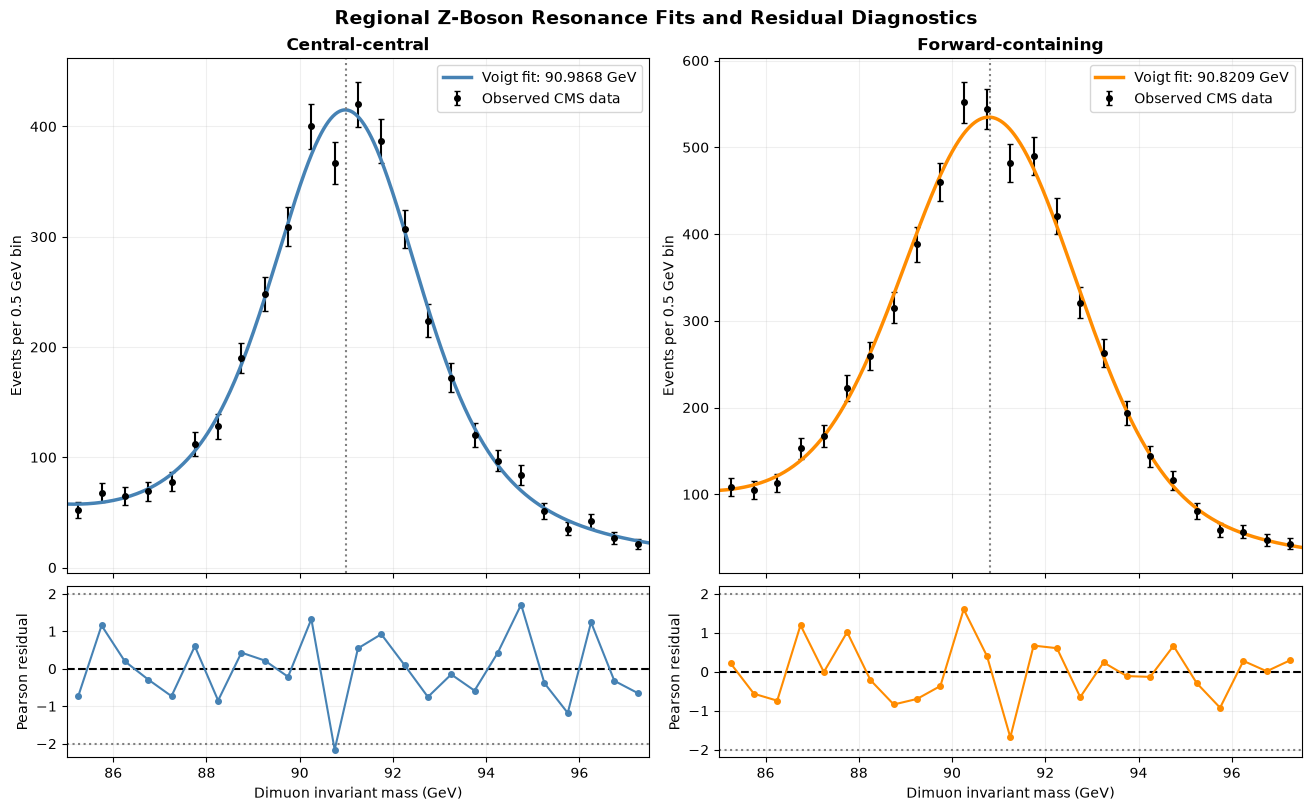

In [151]:

# Section 17: Smooth regional Voigt fits and residuals

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile
from numpy.polynomial.legendre import leggauss

region_centers = (
    region_edges[:-1] + region_edges[1:]
) / 2

# Fine mass grid for smooth fitted curves
x_smooth = np.linspace(85, 97.5, 500)

# 12-point integration across 0.5 GeV bins
nodes, weights = leggauss(12)
half_width = 0.25
sample_points = (
    x_smooth[:, None] + half_width * nodes
)

regions = [
    "Central-central",
    "Forward-containing"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 8),
    sharex="col",
    gridspec_kw={"height_ratios": [3, 1]},
    constrained_layout=True
)

for j, region in enumerate(regions):

    data = region_results[region]

    observed = data["counts"]
    predicted = data["predicted"]

    # Previously fitted parameters
    S, m0, gamma, sigma, B0, k = data["params"]

    # Smooth bin-averaged expected counts
    smooth_density = (
        S * voigt_profile(
            sample_points - m0, sigma, gamma
        )
        + (B0 / 0.5)
        * np.exp(k * (sample_points - 91))
    )

    smooth_counts = (
        half_width
        * np.sum(weights * smooth_density, axis=1)
    )

    # Pearson residuals at original bin centers
    residuals = (
        (observed - predicted)
        / np.sqrt(np.maximum(predicted, 1e-12))
    )

    # Upper panel: observed data and smooth fit
    axes[0, j].errorbar(
        region_centers,
        observed,
        yerr=np.sqrt(np.maximum(observed, 1)),
        fmt="o",
        color="black",
        markersize=4,
        capsize=2,
        label="Observed CMS data"
    )

    axes[0, j].plot(
        x_smooth,
        smooth_counts,
        color="steelblue" if j == 0 else "darkorange",
        linewidth=2.5,
        label=f"Voigt fit: {m0:.4f} GeV"
    )

    axes[0, j].axvline(
        m0,
        color="gray",
        linestyle=":",
        linewidth=1.5
    )

    axes[0, j].set_title(
        region,
        fontweight="bold"
    )

    axes[0, j].set_ylabel("Events per 0.5 GeV bin")
    axes[0, j].legend()
    axes[0, j].grid(alpha=0.2)

    # Lower panel: original unsmoothed residuals
    axes[1, j].axhline(
        0, color="black", linestyle="--"
    )

    axes[1, j].axhline(
        2, color="gray", linestyle=":"
    )

    axes[1, j].axhline(
        -2, color="gray", linestyle=":"
    )

    axes[1, j].plot(
        region_centers,
        residuals,
        "o-",
        color="steelblue" if j == 0 else "darkorange",
        markersize=4
    )

    axes[1, j].set_xlabel(
        "Dimuon invariant mass (GeV)"
    )

    axes[1, j].set_ylabel("Pearson residual")
    axes[1, j].set_xlim(85, 97.5)
    axes[1, j].grid(alpha=0.2)

fig.suptitle(
    "Regional Z-Boson Resonance Fits and Residual Diagnostics",
    fontsize=14,
    fontweight="bold"
)

plt.show()


In [61]:
#verfiy 2 regional fits

from scipy.optimize import minimize
from scipy.special import gammaln
import numpy as np
import pandas as pd

scale = np.array([10000, 1, 1, 1, 100, 0.1])

scaled_bounds = [
    tuple(np.array(b) / s)
    for b, s in zip(bounds_v, scale)
]

verified_regions = {}

for region in regions:

    counts_region = region_results[region]["counts"]

    def nll_scaled(z):
        mu = expected_region(z * scale)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return np.inf

        return np.sum(
            mu - counts_region * np.log(mu)
            + gammaln(counts_region + 1)
        )

    initial = region_results[region]["params"]

    solutions = []

    for sigma_start in [0.7, 1.2, 1.8]:
        start = initial.copy()
        start[3] = sigma_start

        res = minimize(
            nll_scaled,
            start / scale,
            method="L-BFGS-B",
            bounds=scaled_bounds,
            options={
                "maxiter": 20000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if res.success and np.isfinite(res.fun):
            solutions.append(res)

    if not solutions:
        raise RuntimeError(f"Fit failed: {region}")

    best = min(solutions, key=lambda r: r.fun)

    verified_regions[region] = {
        "params": best.x * scale,
        "nll": best.fun,
        "counts": counts_region
    }

    print(f"\n{region}")
    print("Verified center:",
          round(best.x[1], 6), "GeV")
    print("NLL:", round(best.fun, 6))

m_c = verified_regions["Central-central"]["params"][1]
m_f = verified_regions["Forward-containing"]["params"][1]

print(
    "\nVerified center difference:",
    round(m_c - m_f, 6), "GeV"
)



Central-central
Verified center: 90.986807 GeV
NLL: 91.802739

Forward-containing
Verified center: 90.820875 GeV
NLL: 94.835043

Verified center difference: 0.165932 GeV


## 18. Profile-Likelihood Uncertainty by Detector Region

The statistically optimized resonance centers are compared
between the central-central and forward-containing samples.

For each category, the resonance-center parameter is
scanned while the remaining Voigt-plus-exponential model
parameters are reoptimized.

Approximate 68% confidence intervals are determined using
the profile-likelihood threshold:

$$
2\Delta\mathrm{NLL}=1
$$

The statistical uncertainties will be used to assess
the difference between the regional fitted centers.

In [64]:

from scipy.optimize import minimize, brentq
from scipy.special import gammaln
import numpy as np
import pandas as pd

# Nuisance parameters: S, gamma, sigma, B0, k
ids = [0, 2, 3, 4, 5]

bounds_array = np.array(
    [bounds_v[i] for i in ids], dtype=float
)

low = bounds_array[:, 0]
span = bounds_array[:, 1] - low

def regional_profile(region):

    best = verified_regions[region]["params"].copy()
    counts = verified_regions[region]["counts"]

    def nll(params):
        mu = expected_region(params)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return np.inf

        return np.sum(
            mu - counts * np.log(mu)
            + gammaln(counts + 1)
        )

    nll_min = nll(best)
    center = best[1]

    z0 = (best[ids] - low) / span

    def profile_q(trial_mass):

        def objective(z):
            params = best.copy()
            params[1] = trial_mass
            params[ids] = low + z * span
            return nll(params)

        starts = [
            z0,
            np.clip(z0 + 0.01, 0, 1),
            np.clip(z0 - 0.01, 0, 1)
        ]

        solutions = []

        for start in starts:
            res = minimize(
                objective,
                start,
                method="L-BFGS-B",
                bounds=[(0, 1)] * len(ids),
                options={
                    "maxiter": 15000,
                    "ftol": 1e-12,
                    "gtol": 1e-8,
                    "maxls": 50
                }
            )

            if res.success and np.isfinite(res.fun):
                solutions.append(res.fun)

        if not solutions:
            raise RuntimeError(
                f"Profile failed: {region}, {trial_mass}"
            )

        return 2 * (min(solutions) - nll_min)

    lower = brentq(
        lambda m: profile_q(m) - 1,
        center - 0.25, center,
        xtol=1e-6
    )

    upper = brentq(
        lambda m: profile_q(m) - 1,
        center, center + 0.25,
        xtol=1e-6
    )

    return {
        "Region": region,
        "Center (GeV)": center,
        "Lower 68% (GeV)": lower,
        "Upper 68% (GeV)": upper,
        "Minus error (GeV)": center - lower,
        "Plus error (GeV)": upper - center
    }

interval_results = pd.DataFrame([
    regional_profile("Central-central"),
    regional_profile("Forward-containing")
])

display(interval_results.round(5))


,Region,Center (GeV),Lower 68% (GeV),Upper 68% (GeV),Minus error (GeV),Plus error (GeV)
0,Central-central,90.98681,90.93834,91.03354,0.04846,0.04673
1,Forward-containing,90.82088,90.77555,90.86563,0.04532,0.04475


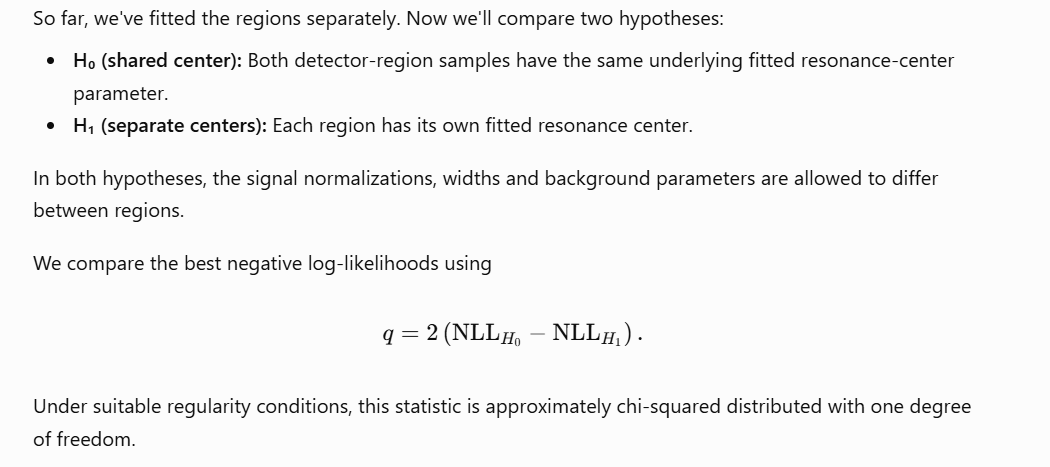

## 19. Hypothesis Test for Regional Resonance Centers

A likelihood-ratio test is performed to investigate whether
the two pseudorapidity categories require different resonance
centers.

H0: The central-central and forward-containing samples share
    a common fitted resonance center.

H1: Each category has an independently fitted resonance center.

The other Voigt and background parameters remain independent
between the two regions.

The test compares the optimized Poisson negative
log-likelihoods under both hypotheses.

In [68]:

from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import chi2
import numpy as np

regions = ["Central-central", "Forward-containing"]

# Validated separate-region results
pc = verified_regions["Central-central"]["params"].copy()
pf = verified_regions["Forward-containing"]["params"].copy()

counts_c = verified_regions["Central-central"]["counts"]
counts_f = verified_regions["Forward-containing"]["counts"]

# Nuisance parameter indices:
# S, gamma, sigma, B0, k
nuisance_ids = [0, 2, 3, 4, 5]

# Scales for numerical optimization
nuisance_scale = np.array(
    [10000, 1, 1, 100, 0.1]
)

joint_scale = np.concatenate([
    [1.0], nuisance_scale, nuisance_scale
])

# The shared-center model has 11 parameters
joint_bounds = (
    [bounds_v[1]]
    + [bounds_v[i] for i in nuisance_ids]
    + [bounds_v[i] for i in nuisance_ids]
)

scaled_bounds = [
    (lo/s, hi/s)
    for (lo, hi), s in zip(joint_bounds, joint_scale)
]

def region_nll(params, observed):
    predicted = expected_region(params)

    if np.any(~np.isfinite(predicted)) or np.any(predicted <= 0):
        return np.inf

    return np.sum(
        predicted
        - observed * np.log(predicted)
        + gammaln(observed + 1)
    )

def common_center_nll(z):
    p = z * joint_scale

    shared_center = p[0]

    pars_c = pc.copy()
    pars_f = pf.copy()

    pars_c[1] = shared_center
    pars_f[1] = shared_center

    pars_c[nuisance_ids] = p[1:6]
    pars_f[nuisance_ids] = p[6:11]

    return (
        region_nll(pars_c, counts_c)
        + region_nll(pars_f, counts_f)
    )

# Fit the shared-center hypothesis
solutions = []

for center_start in [
    (pc[1] + pf[1])/2,
    pc[1],
    pf[1]
]:
    initial = np.concatenate([
        [center_start],
        pc[nuisance_ids],
        pf[nuisance_ids]
    ])

    result_joint = minimize(
        common_center_nll,
        initial / joint_scale,
        method="L-BFGS-B",
        bounds=scaled_bounds,
        options={
            "maxiter": 20000,
            "ftol": 1e-12,
            "gtol": 1e-8,
            "maxls": 50
        }
    )

    if result_joint.success and np.isfinite(result_joint.fun):
        solutions.append(result_joint)

if not solutions:
    raise RuntimeError("Shared-center fit failed.")

best_joint = min(solutions, key=lambda r: r.fun)

# Separate-center likelihood from validated fits
nll_separate = (
    region_nll(pc, counts_c)
    + region_nll(pf, counts_f)
)

nll_shared = best_joint.fun

# Likelihood-ratio statistic
q = 2 * (nll_shared - nll_separate)

if q < -1e-5:
    raise RuntimeError(
        "Shared-center model fitted better than separate-center "
        "model. Recheck numerical optimization."
    )

p_value = chi2.sf(max(q, 0), df=1)

shared_center = (
    best_joint.x * joint_scale
)[0]

print("SHARED-CENTER HYPOTHESIS TEST")
print("--------------------------------")
print(f"Shared center: {shared_center:.6f} GeV")
print(f"Separate-model NLL: {nll_separate:.6f}")
print(f"Shared-model NLL: {nll_shared:.6f}")
print(f"Likelihood-ratio q: {q:.4f}")
print(f"Approximate p-value: {p_value:.6g}")


SHARED-CENTER HYPOTHESIS TEST
--------------------------------
Shared center: 90.904315 GeV
Separate-model NLL: 186.637782
Shared-model NLL: 189.971462
Likelihood-ratio q: 6.6674
Approximate p-value: 0.00981945


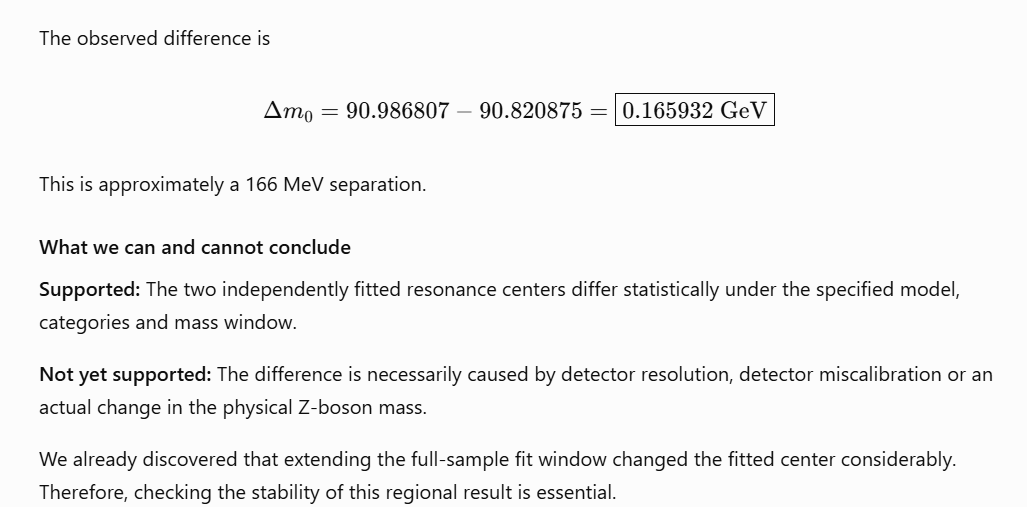}

## 20. Robustness of the Detector-Region Difference

The fitted difference between the central-central and
forward-containing resonance centers was statistically
significant under the baseline model.

To examine whether this result depends on analysis choices,
both categories are refitted using alternative bin widths
and fitting ranges.

The same reconstruction method, Voigt-plus-exponential
model and Poisson likelihood are retained throughout.

Regional differences are compared without selecting
configurations based on agreement with the reference mass.

In [72]:

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss

nodes, weights = leggauss(12)

parameter_scale = np.array(
    [10000, 1, 1, 1, 100, 0.1]
)

scaled_bounds = [
    (lo/s, hi/s)
    for (lo, hi), s in zip(bounds_v, parameter_scale)
]

def fit_region_robust(region, bin_width, low_mass, high_mass):

    values = df2.loc[
        df2["region"] == region,
        "M_alt_corrected"
    ].dropna().to_numpy()

    # Construct true bin widths,
    # allowing a shorter final bin
    edges = np.arange(
        low_mass, high_mass, bin_width
    )
    edges = np.append(edges, high_mass)

    observed, _ = np.histogram(values, bins=edges)

    mid = (edges[:-1] + edges[1:]) / 2
    half = np.diff(edges) / 2
    points = mid[:, None] + half[:, None]*nodes

    def expected(params):
        S, m0, gamma, sigma, B0, k = params

        signal = (
            S * half *
            np.sum(
                weights * voigt_profile(
                    points-m0, sigma, gamma
                ),
                axis=1
            )
        )

        background = (
            half * np.sum(
                weights * (B0/0.5)
                * np.exp(k*(points-91)),
                axis=1
            )
        )

        return signal + background

    def nll(z):
        predicted = expected(z*parameter_scale)

        if np.any(~np.isfinite(predicted)) or np.any(predicted <= 0):
            return 1e100

        return np.sum(
            predicted
            - observed*np.log(predicted)
            + gammaln(observed+1)
        )

    initial = verified_regions[region]["params"].copy()

    solutions = []

    for sigma_start in [0.8, 1.2, 1.8]:
        start = initial.copy()
        start[3] = sigma_start

        res = minimize(
            nll,
            start/parameter_scale,
            method="L-BFGS-B",
            bounds=scaled_bounds,
            options={
                "maxiter": 15000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if res.success and np.isfinite(res.fun):
            solutions.append(res)

    if not solutions:
        raise RuntimeError(f"No converged fit: {region}")

    best = min(solutions, key=lambda r: r.fun)
    params = best.x * parameter_scale
    predicted = expected(params)

    positive = observed > 0
    term = np.zeros_like(observed, dtype=float)

    term[positive] = observed[positive] * np.log(
        observed[positive]/predicted[positive]
    )

    deviance = 2*np.sum(
        term - (observed-predicted)
    )

    dof = len(observed)-len(params)

    return {
        "center": params[1],
        "deviance_dof": deviance/dof,
        "n_events": observed.sum(),
        "params": params,
        "converged": best.success
    }


# Compare identical settings for both regions
settings = [
    (0.5, 85, 97.5),
    (1.0, 85, 97.5),
    (0.5, 83, 99),
    (1.0, 83, 99)
]

rows = []

for width, low, high in settings:

    central = fit_region_robust(
        "Central-central", width, low, high
    )

    forward = fit_region_robust(
        "Forward-containing", width, low, high
    )

    rows.append({
        "Bin width": width,
        "Fit range": f"{low}-{high}",
        "Central mass": central["center"],
        "Forward mass": forward["center"],
        "Difference": (
            central["center"]-forward["center"]
        ),
        "Central dev/dof": central["deviance_dof"],
        "Forward dev/dof": forward["deviance_dof"]
    })

regional_robustness = pd.DataFrame(rows)

display(regional_robustness.round(5))


,Bin width,Fit range,Central mass,Forward mass,Difference,Central dev/dof,Forward dev/dof
0,0.5,85-97.5,90.98681,90.82088,0.16593,1.00346,0.69363
1,1.0,85-97.5,90.99797,90.82334,0.17462,0.84500,0.76333
2,0.5,83-99,90.95723,90.70796,0.24927,1.21783,1.67172
3,1.0,83-99,90.96703,90.70454,0.26249,1.42710,3.41905


In [74]:

# Identify events with pT inconsistencies
threshold = 0.01  # GeV, exploratory threshold

df2["pt_inconsistent"] = (
    (df2["pt1_diff"] > threshold) |
    (df2["pt2_diff"] > threshold)
)

# Count flagged events in each detector region
quality_summary = (
    df2.groupby("region")["pt_inconsistent"]
    .agg(
        Total_events="count",
        Flagged_events="sum",
        Flagged_fraction="mean"
    )
)

quality_summary["Flagged_percentage"] = (
    100 * quality_summary["Flagged_fraction"]
)

display(quality_summary.round(3))

# Compare quality flags in the resonance window
in_window = df2["M_alt_corrected"].between(
    85, 97.5, inclusive="left"
)

window_quality = (
    df2.loc[in_window]
    .groupby("region")["pt_inconsistent"]
    .agg(
        Events="count",
        Flagged="sum",
        Flagged_fraction="mean"
    )
)

window_quality["Flagged_percentage"] = (
    100 * window_quality["Flagged_fraction"]
)

print("\nWithin the resonance fitting window:")
display(window_quality.round(3))


,Total_events,Flagged_events,Flagged_fraction,Flagged_percentage
region,,,,
Central-central,19094,1142,0.060,5.981
Forward-containing,64667,2982,0.046,4.611



Within the resonance fitting window:


,Events,Flagged,Flagged_fraction,Flagged_percentage
region,,,,
Central-central,4073,30,0.007,0.737
Forward-containing,6106,32,0.005,0.524


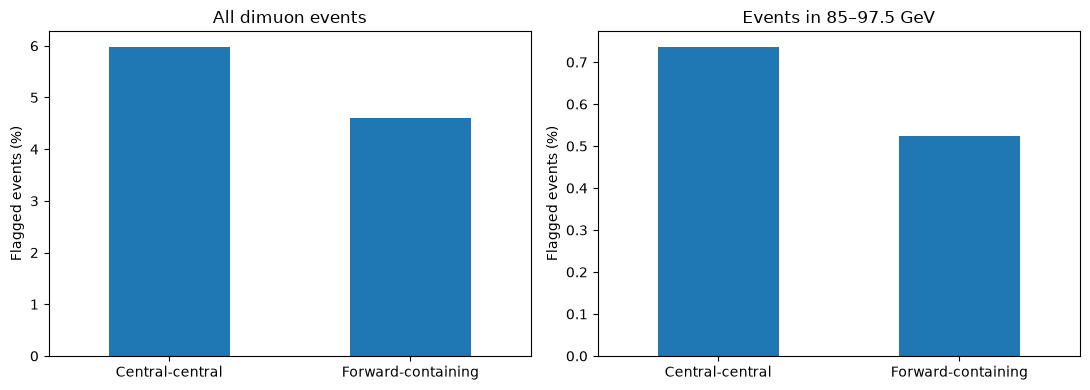

In [76]:
#visualize regional discrepency rate

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

quality_summary["Flagged_percentage"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("All dimuon events")
axes[0].set_ylabel("Flagged events (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

window_quality["Flagged_percentage"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Events in 85–97.5 GeV")
axes[1].set_ylabel("Flagged events (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


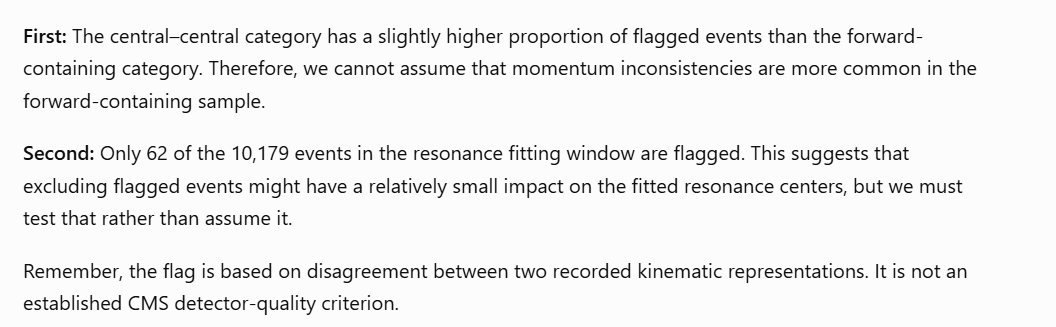

In [79]:
#updated regional fitting function

from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss

import numpy as np
import pandas as pd

# Numerical integration
nodes, weights = leggauss(12)

# Parameter order:
# S, m0, gamma, sigma, B0, k

parameter_scale = np.array([
    10000, 1, 1, 1, 100, 0.1
])

scaled_bounds = [
    (lo / s, hi / s)
    for (lo, hi), s in zip(bounds_v, parameter_scale)
]


def fit_region_robust(
    region,
    bin_width,
    low_mass,
    high_mass,
    exclude_flagged=False
):
    """
    Fit a Voigt signal plus exponential background
    using Poisson maximum likelihood.

    Parameters
    ----------
    region : str
        'Central-central' or 'Forward-containing'

    bin_width : float
        Histogram bin width in GeV.

    low_mass, high_mass : float
        Fitting window boundaries in GeV.

    exclude_flagged : bool
        If True, exclude events flagged for
        transverse-momentum inconsistency.

    Returns
    -------
    dict
        Fitted center, fit diagnostics,
        event count and fitted parameters.
    """

    # -----------------------------------------
    # 1. Select detector-region events
    # -----------------------------------------

    selection = df2["region"] == region

    if exclude_flagged:
        selection = (
            selection & ~df2["pt_inconsistent"]
        )

    values = df2.loc[
        selection, "M_alt_corrected"
    ].dropna().to_numpy()

    # -----------------------------------------
    # 2. Construct histogram
    # -----------------------------------------

    edges = np.arange(
        low_mass,
        high_mass,
        bin_width
    )

    edges = np.append(edges, high_mass)

    observed, _ = np.histogram(
        values, bins=edges
    )

    # -----------------------------------------
    # 3. Numerical integration points
    # -----------------------------------------

    mid = (edges[:-1] + edges[1:]) / 2
    half = np.diff(edges) / 2

    points = (
        mid[:, None]
        + half[:, None] * nodes
    )

    # -----------------------------------------
    # 4. Voigt + exponential background
    # -----------------------------------------

    def expected(params):

        S, m0, gamma, sigma, B0, k = params

        # Signal contribution
        signal = (
            S * half *
            np.sum(
                weights * voigt_profile(
                    points - m0,
                    sigma,
                    gamma
                ),
                axis=1
            )
        )

        # Background contribution
        background = (
            half *
            np.sum(
                weights *
                (B0 / 0.5) *
                np.exp(k * (points - 91)),
                axis=1
            )
        )

        return signal + background

    # -----------------------------------------
    # 5. Poisson negative log-likelihood
    # -----------------------------------------

    def nll(z):

        params = z * parameter_scale

        predicted = expected(params)

        if (
            np.any(~np.isfinite(predicted))
            or np.any(predicted <= 0)
        ):
            return 1e100

        return np.sum(
            predicted
            - observed * np.log(predicted)
            + gammaln(observed + 1)
        )

    # -----------------------------------------
    # 6. Initial parameter estimates
    # -----------------------------------------

    initial = verified_regions[
        region
    ]["params"].copy()

    # -----------------------------------------
    # 7. Multi-start optimization
    # -----------------------------------------

    solutions = []

    for sigma_start in [0.8, 1.2, 1.8]:

        start = initial.copy()

        start[3] = sigma_start

        result = minimize(
            nll,
            start / parameter_scale,
            method="L-BFGS-B",
            bounds=scaled_bounds,
            options={
                "maxiter": 15000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if (
            result.success
            and np.isfinite(result.fun)
        ):
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            f"No converged fit for {region}"
        )

    best = min(
        solutions,
        key=lambda r: r.fun
    )

    params = best.x * parameter_scale

    predicted = expected(params)

    # -----------------------------------------
    # 8. Poisson deviance
    # -----------------------------------------

    positive = observed > 0

    term = np.zeros_like(
        observed,
        dtype=float
    )

    term[positive] = (
        observed[positive]
        * np.log(
            observed[positive]
            / predicted[positive]
        )
    )

    deviance = 2 * np.sum(
        term - (observed - predicted)
    )

    dof = len(observed) - len(params)

    # -----------------------------------------
    # 9. Return fitting results
    # -----------------------------------------

    return {
        "region": region,
        "center": params[1],
        "gamma": params[2],
        "sigma": params[3],
        "deviance": deviance,
        "deviance_dof": deviance / dof,
        "n_events": int(observed.sum()),
        "params": params,
        "nll": best.fun,
        "converged": best.success
    }


In [81]:

# Compare the original and unflagged samples

quality_fit_results = []

for exclude in [False, True]:

    label = (
        "Unflagged events"
        if exclude else "All events"
    )

    central = fit_region_robust(
        "Central-central",
        0.5, 85, 97.5,
        exclude_flagged=exclude
    )

    forward = fit_region_robust(
        "Forward-containing",
        0.5, 85, 97.5,
        exclude_flagged=exclude
    )

    quality_fit_results.append({
        "Sample": label,
        "Central events": central["n_events"],
        "Forward events": forward["n_events"],
        "Central center": central["center"],
        "Forward center": forward["center"],
        "Center difference": (
            central["center"] - forward["center"]
        ),
        "Central dev/dof": central["deviance_dof"],
        "Forward dev/dof": forward["deviance_dof"]
    })

quality_fit_table = pd.DataFrame(
    quality_fit_results
)

display(quality_fit_table.round(5))

# Quantify changes after excluding flagged events
baseline = quality_fit_table.iloc[0]
unflagged = quality_fit_table.iloc[1]

print("\nChange in regional center difference:")
print(
    round(
        1000 * (
            unflagged["Center difference"]
            - baseline["Center difference"]
        ), 3
    ),
    "MeV"
)

print("\nChange in central fitted center:")
print(
    round(
        1000 * (
            unflagged["Central center"]
            - baseline["Central center"]
        ), 3
    ),
    "MeV"
)

print("\nChange in forward fitted center:")
print(
    round(
        1000 * (
            unflagged["Forward center"]
            - baseline["Forward center"]
        ), 3
    ),
    "MeV"
)


,Sample,Central events,Forward events,Central center,Forward center,Center difference,Central dev/dof,Forward dev/dof
0,All events,4073,6106,90.98681,90.82088,0.16593,1.00346,0.69363
1,Unflagged events,4043,6074,90.98757,90.82120,0.16637,0.98242,0.68257



Change in regional center difference:
0.439 MeV

Change in central fitted center:
0.766 MeV

Change in forward fitted center:
0.327 MeV


## 23. Bootstrap Validation of the Regional Mass Difference

The statistical uncertainty of the central-minus-forward
resonance-center difference is estimated by nonparametric
bootstrap resampling.

Events are resampled independently with replacement within
each detector-region category. Both samples are refitted
using the same Voigt-plus-exponential model and baseline
85–97.5 GeV fitting window.

The resulting distribution of center differences provides
an independent check on statistical precision.

This bootstrap does not include systematic uncertainties
from detector calibration, model choice or fitting range.

Successful bootstrap samples: 499
Failed bootstrap samples: 1
Mean difference (GeV): 0.17353692275618016
Bootstrap standard error (GeV): 0.06015366884806503
Percentile 95% interval (GeV): [0.05546872 0.28877834]


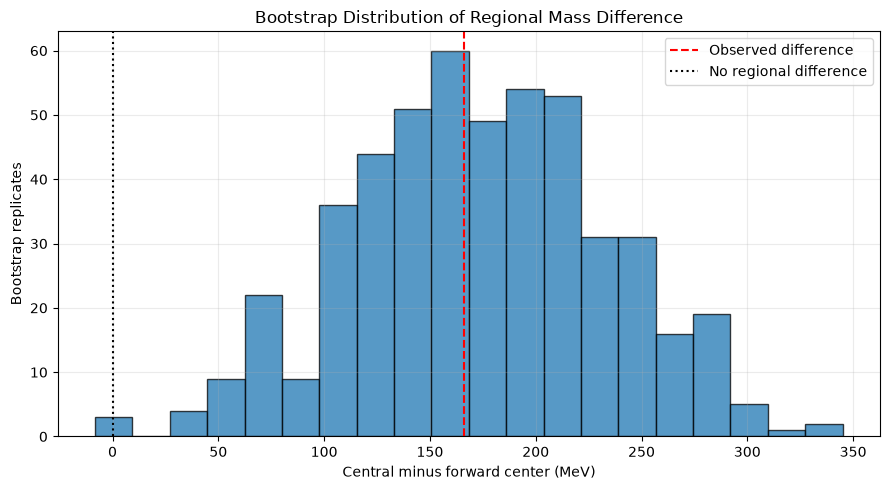

In [86]:

from scipy.optimize import minimize
from scipy.special import gammaln
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3043)

# Initial exploratory bootstrap
n_bootstrap = 500 #100

regions = ["Central-central", "Forward-containing"]

# Use the same fitting window as the baseline
bootstrap_edges = np.arange(85, 98, 0.5)

# Extract independent event samples
samples = {}

for region in regions:
    samples[region] = df2.loc[
        (df2["region"] == region)
        & df2["M_alt_corrected"].between(
            85, 97.5, inclusive="left"
        ),
        "M_alt_corrected"
    ].to_numpy()

# Use the original regional-fit model
# expected_region() uses the same 0.5 GeV bins
scales = np.array([10000, 1, 1, 1, 100, 0.1])

scaled_bounds = [
    (lo/s, hi/s)
    for (lo, hi), s in zip(bounds_v, scales)
]

def fit_bootstrap_sample(sample, region):

    observed, _ = np.histogram(
        sample, bins=bootstrap_edges
    )

    def objective(z):
        mu = expected_region(z * scales)

        if np.any(~np.isfinite(mu)) or np.any(mu <= 0):
            return 1e100

        return np.sum(
            mu - observed*np.log(mu)
            + gammaln(observed+1)
        )

    initial = verified_regions[region]["params"]

    result = minimize(
        objective,
        initial/scales,
        method="L-BFGS-B",
        bounds=scaled_bounds,
        options={
            "maxiter": 10000,
            "ftol": 1e-10
        }
    )

    if not result.success:
        return np.nan

    return (result.x*scales)[1]


differences = []

for b in range(n_bootstrap):

    fitted_centers = []

    for region in regions:

        original = samples[region]

        resampled = rng.choice(
            original,
            size=len(original),
            replace=True
        )

        center = fit_bootstrap_sample(
            resampled, region
        )

        fitted_centers.append(center)

    differences.append(
        fitted_centers[0]-fitted_centers[1]
    )

differences = np.array(differences)

valid = differences[np.isfinite(differences)]

print("Successful bootstrap samples:", len(valid))
print("Failed bootstrap samples:",
      len(differences)-len(valid))

if len(valid) < 0.9*n_bootstrap:
    raise RuntimeError(
        "Too many bootstrap fits failed."
    )

print("Mean difference (GeV):", valid.mean())
print("Bootstrap standard error (GeV):", valid.std(ddof=1))

print(
    "Percentile 95% interval (GeV):",
    np.percentile(valid, [2.5, 97.5])
)

plt.figure(figsize=(9, 5))

plt.hist(
    valid*1000,
    bins=20,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    165.932,
    color="red",
    linestyle="--",
    label="Observed difference"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="No regional difference"
)

plt.xlabel("Central minus forward center (MeV)")
plt.ylabel("Bootstrap replicates")
plt.title("Bootstrap Distribution of Regional Mass Difference")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [87]:

# Section 24: Bootstrap stability assessment

import numpy as np
import pandas as pd

valid = differences[np.isfinite(differences)]

print("Successful replicates:", len(valid))
print("Failed replicates:",
      len(differences) - len(valid))

checkpoints = [100, 200, 300, 400, 500]
summary = []

for n in checkpoints:
    if len(valid) < n:
        continue

    sample = valid[:n]

    lower, upper = np.percentile(
        sample, [2.5, 97.5]
    )

    summary.append({
        "Replicates": n,
        "Mean (MeV)": sample.mean() * 1000,
        "SE (MeV)": sample.std(ddof=1) * 1000,
        "95% lower (MeV)": lower * 1000,
        "95% upper (MeV)": upper * 1000
    })

bootstrap_stability = pd.DataFrame(summary)

display(bootstrap_stability.round(2))

# Save numerical results for reproducibility
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

np.save(
    results_dir / "regional_bootstrap_500.npy",
    differences
)

bootstrap_stability.to_csv(
    results_dir / "bootstrap_stability.csv",
    index=False
)


Successful replicates: 499
Failed replicates: 1


,Replicates,Mean (MeV),SE (MeV),95% lower (MeV),95% upper (MeV)
0,100,174.15,57.80,70.65,283.89
1,200,175.63,59.94,57.68,289.68
2,300,173.87,60.95,53.55,287.91
3,400,175.32,60.54,53.88,288.04


## 25. Bootstrap Convergence and Final Validation

A nonparametric bootstrap with 500 resampling attempts was
performed to estimate the uncertainty of the fitted
central-minus-forward resonance-center difference.

The bootstrap distribution, confidence-interval convergence,
failed optimizations and extreme estimates were examined.

The resulting confidence interval quantifies statistical
sampling uncertainty under the baseline reconstruction,
fitting model and selected mass window.

In [91]:

# Final bootstrap validation

bootstrap_values = np.asarray(differences, dtype=float)

successful = np.isfinite(bootstrap_values)
valid = bootstrap_values[successful]

failed_indices = np.where(~successful)[0]

observed_difference = (
    verified_regions["Central-central"]["params"][1]
    - verified_regions["Forward-containing"]["params"][1]
)

print("Total attempts:", len(bootstrap_values))
print("Successful fits:", successful.sum())
print("Failed fits:", len(failed_indices))
print("Failed replicate indices:", failed_indices.tolist())

print("\nFINAL BOOTSTRAP SUMMARY")
print("-" * 35)

print(f"Observed difference: {observed_difference*1000:.3f} MeV")
print(f"Bootstrap mean: {np.mean(valid)*1000:.3f} MeV")
print(f"Bootstrap median: {np.median(valid)*1000:.3f} MeV")
print(f"Bootstrap SE: {np.std(valid, ddof=1)*1000:.3f} MeV")

lower, upper = np.percentile(valid, [2.5, 97.5])

print(f"95% lower limit: {lower*1000:.3f} MeV")
print(f"95% upper limit: {upper*1000:.3f} MeV")

print("\nExtreme bootstrap estimates:")
print(f"Minimum: {valid.min()*1000:.3f} MeV")
print(f"Maximum: {valid.max()*1000:.3f} MeV")

print("\nBootstrap estimates <= 0:",
      (valid <= 0).sum())


Total attempts: 500
Successful fits: 499
Failed fits: 1
Failed replicate indices: [164]

FINAL BOOTSTRAP SUMMARY
-----------------------------------
Observed difference: 165.932 MeV
Bootstrap mean: 173.537 MeV
Bootstrap median: 172.540 MeV
Bootstrap SE: 60.154 MeV
95% lower limit: 55.469 MeV
95% upper limit: 288.778 MeV

Extreme bootstrap estimates:
Minimum: -8.281 MeV
Maximum: 345.038 MeV

Bootstrap estimates <= 0: 2


In [93]:


from pathlib import Path

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

np.save(
    results_dir / "regional_bootstrap_500.npy",
    bootstrap_values
)

final_bootstrap_summary = pd.DataFrame([{
    "Observed_difference_GeV": observed_difference,
    "Bootstrap_mean_GeV": valid.mean(),
    "Bootstrap_SE_GeV": valid.std(ddof=1),
    "CI_95_lower_GeV": lower,
    "CI_95_upper_GeV": upper,
    "Successful_replicates": len(valid),
    "Failed_replicates": len(failed_indices)
}])

final_bootstrap_summary.to_csv(
    results_dir / "regional_bootstrap_summary.csv",
    index=False
)

display(final_bootstrap_summary.round(5))


,Observed_difference_GeV,Bootstrap_mean_GeV,Bootstrap_SE_GeV,CI_95_lower_GeV,CI_95_upper_GeV,Successful_replicates,Failed_replicates
0,0.16593,0.17354,0.06015,0.05547,0.28878,499,1


In [95]:

import pandas as pd
from pathlib import Path

# Final validated results available so far
summary = pd.DataFrame([
    {
        "Analysis": "Full sample",
        "Center_GeV": 90.895754,
        "Lower_68_GeV": 90.860318,
        "Upper_68_GeV": 90.928099,
        "Model": "Voigt + exponential",
        "Deviance_per_dof": 0.973
    },
    {
        "Analysis": "Central-central",
        "Center_GeV": 90.986807,
        "Lower_68_GeV": 90.93834,
        "Upper_68_GeV": 91.03354,
        "Model": "Voigt + exponential",
        "Deviance_per_dof": 1.0035
    },
    {
        "Analysis": "Forward-containing",
        "Center_GeV": 90.820875,
        "Lower_68_GeV": 90.77555,
        "Upper_68_GeV": 90.86563,
        "Model": "Voigt + exponential",
        "Deviance_per_dof": 0.6936
    }
])

summary["Minus_error_GeV"] = (
    summary["Center_GeV"] - summary["Lower_68_GeV"]
)

summary["Plus_error_GeV"] = (
    summary["Upper_68_GeV"] - summary["Center_GeV"]
)

display(summary.round(5))

# Save the table
output_path = PROJECT_ROOT / "results"
output_path.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    output_path / "final_resonance_summary.csv",
    index=False
)

print("Saved:", output_path / "final_resonance_summary.csv")


,Analysis,Center_GeV,Lower_68_GeV,Upper_68_GeV,Model,Deviance_per_dof,Minus_error_GeV,Plus_error_GeV
0,Full sample,90.89575,90.86032,90.92810,Voigt + exponential,0.9730,0.03544,0.03235
1,Central-central,90.98681,90.93834,91.03354,Voigt + exponential,1.0035,0.04847,0.04673
2,Forward-containing,90.82088,90.77555,90.86563,Voigt + exponential,0.6936,0.04533,0.04475


Saved: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\results\final_resonance_summary.csv


In [97]:

# Summarize the individual investigation

regional_comparison = pd.DataFrame([{
    "Observed_difference_MeV": 165.932,
    "Bootstrap_mean_MeV": 173.537,
    "Bootstrap_SE_MeV": 60.154,
    "Bootstrap_95_lower_MeV": 55.469,
    "Bootstrap_95_upper_MeV": 288.778,
    "Likelihood_ratio_q": 6.6674,
    "Approximate_p_value": 0.00981945,
    "Quality_cut_shift_MeV": 0.439,
    "Bootstrap_successes": 499,
    "Bootstrap_attempts": 500
}])

display(regional_comparison.T)

regional_comparison.to_csv(
    output_path / "regional_comparison_summary.csv",
    index=False
)


,0
Observed_difference_MeV,165.932000
Bootstrap_mean_MeV,173.537000
Bootstrap_SE_MeV,60.154000
Bootstrap_95_lower_MeV,55.469000
Bootstrap_95_upper_MeV,288.778000
Likelihood_ratio_q,6.667400
Approximate_p_value,0.009819
Quality_cut_shift_MeV,0.439000
Bootstrap_successes,499.000000
Bootstrap_attempts,500.000000


## 27. Final Comparison of Regional Resonance Centers

The fitted Z-boson resonance centers for the central-central
and forward-containing muon categories are compared with
their profile-likelihood statistical confidence intervals.

The comparison is intended to visualize the observed
regional difference and its statistical uncertainty.

These intervals do not include systematic uncertainties
associated with the fitting range, detector calibration,
or resonance-model assumptions.

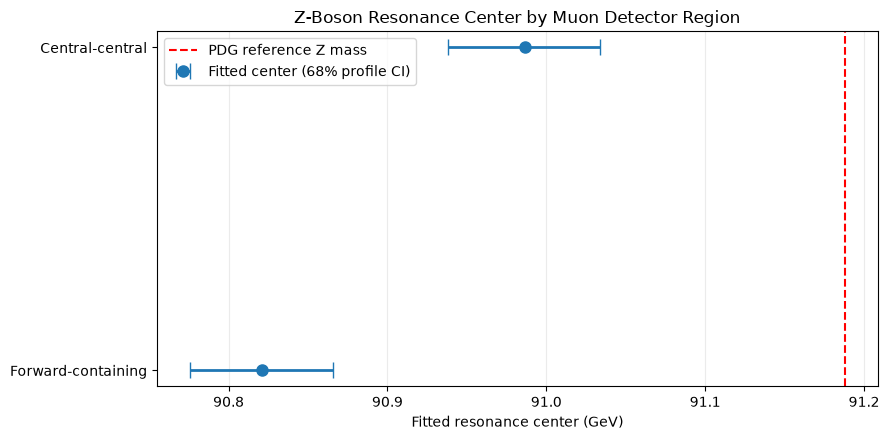

In [100]:
#plot regional mass estimated with unceratninty

import numpy as np
import matplotlib.pyplot as plt

# Use fitted values from the regional profile analysis
regions = interval_results["Region"].tolist()

centers = interval_results["Center (GeV)"].to_numpy()
lower = interval_results["Lower 68% (GeV)"].to_numpy()
upper = interval_results["Upper 68% (GeV)"].to_numpy()

# Asymmetric uncertainty bars
errors = np.vstack([
    centers - lower,
    upper - centers
])

y_positions = np.arange(len(regions))

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.errorbar(
    centers,
    y_positions,
    xerr=errors,
    fmt="o",
    capsize=6,
    markersize=8,
    linewidth=2,
    label="Fitted center (68% profile CI)"
)

# Published Z-boson reference
reference_mass = 91.1879

ax.axvline(
    reference_mass,
    linestyle="--",
    color="red",
    label="PDG reference Z mass"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(regions)
ax.invert_yaxis()

ax.set_xlabel("Fitted resonance center (GeV)")
ax.set_title(
    "Z-Boson Resonance Center by Muon Detector Region"
)

ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()

# Save publication-quality figure
figure_path = PROJECT_ROOT / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_path / "regional_mass_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


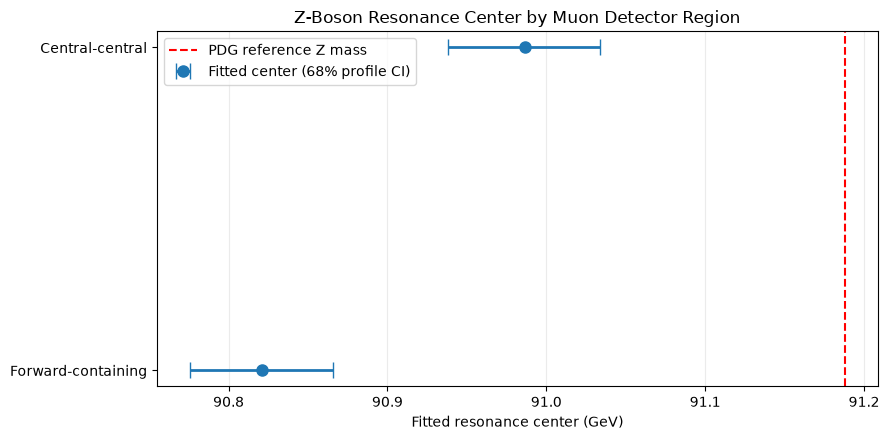

In [102]:
#interval results table

import numpy as np
import matplotlib.pyplot as plt

# Use fitted values from the regional profile analysis
regions = interval_results["Region"].tolist()

centers = interval_results["Center (GeV)"].to_numpy()
lower = interval_results["Lower 68% (GeV)"].to_numpy()
upper = interval_results["Upper 68% (GeV)"].to_numpy()

# Asymmetric uncertainty bars
errors = np.vstack([
    centers - lower,
    upper - centers
])

y_positions = np.arange(len(regions))

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.errorbar(
    centers,
    y_positions,
    xerr=errors,
    fmt="o",
    capsize=6,
    markersize=8,
    linewidth=2,
    label="Fitted center (68% profile CI)"
)

# Published Z-boson reference
reference_mass = 91.1879

ax.axvline(
    reference_mass,
    linestyle="--",
    color="red",
    label="PDG reference Z mass"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(regions)
ax.invert_yaxis()

ax.set_xlabel("Fitted resonance center (GeV)")
ax.set_title(
    "Z-Boson Resonance Center by Muon Detector Region"
)

ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()

# Save publication-quality figure
figure_path = PROJECT_ROOT / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_path / "regional_mass_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Final Presentation Figure — Optimized Z Resonance Fit

The final Voigt-plus-exponential model is plotted against
the reconstructed CERN dimuon counts using the fully
optimized fit parameters.

The lower panel shows Pearson residuals.

The fitted center and its 68% profile-likelihood
statistical confidence interval are displayed.

This figure supersedes the preliminary resonance-fit
visualizations from earlier sections.


C:\Users\Asini Perera\AppData\Local\Temp\ipykernel_26428\2724127183.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


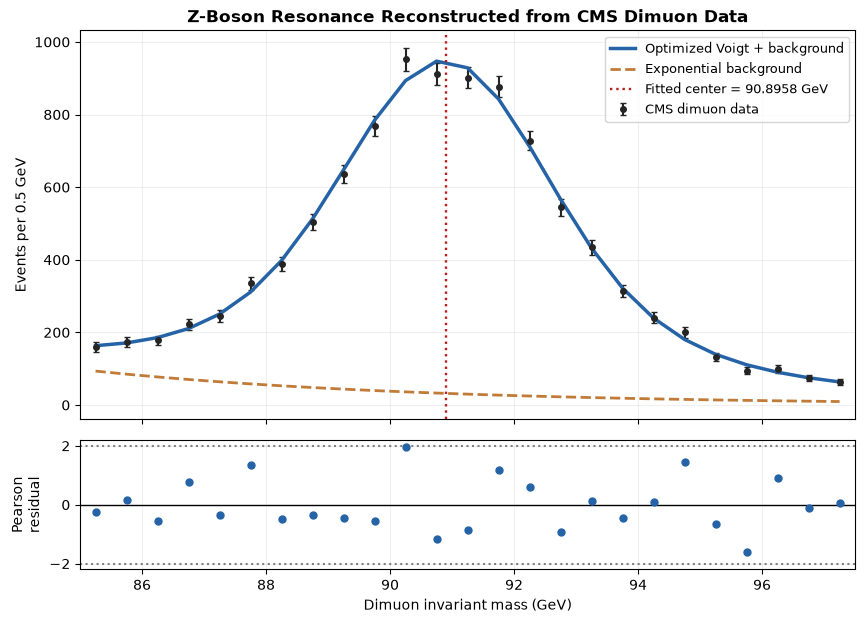

Final fitted center: 90.895754 GeV
Saved final_optimized_z_fit.png and .pdf


In [107]:

# FINAL OPTIMIZED Z-RESONANCE FIGURE
# Notebook 02 - paste at the END

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile
from numpy.polynomial.legendre import leggauss
from pathlib import Path

# 1. Original final fitted parameters
params_final = np.asarray(
    fit_params_validated, dtype=float
)

S, m0, gamma, sigma, B0, k = params_final

# 2. Recreate the exact histogram
plot_edges = np.arange(85, 98, 0.5)
plot_counts, _ = np.histogram(
    df2["M_alt_corrected"].dropna(),
    bins=plot_edges
)

plot_centers = (
    plot_edges[:-1] + plot_edges[1:]
) / 2

plot_width = np.diff(plot_edges)

# 3. Integrate the fitted model over each bin
nodes, weights = leggauss(12)

mid = plot_centers
half = plot_width / 2

points = mid[:, None] + half[:, None] * nodes

signal_density = voigt_profile(
    points - m0, sigma, gamma
)

signal_counts = (
    S * half *
    np.sum(weights * signal_density, axis=1)
)

background_density = (
    B0 / 0.5
) * np.exp(k * (points - 91))

background_counts = (
    half *
    np.sum(weights * background_density, axis=1)
)

total_expected = (
    signal_counts + background_counts
)

# 4. Residuals
residuals = (
    plot_counts - total_expected
) / np.sqrt(total_expected)

# 5. Figure layout
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    gridspec_kw={
        "height_ratios": [3, 1],
        "hspace": 0.08
    }
)

# Observed collision data
ax1.errorbar(
    plot_centers,
    plot_counts,
    yerr=np.sqrt(np.maximum(plot_counts, 1)),
    fmt="o",
    color="#252525",
    markersize=4,
    capsize=2,
    label="CMS dimuon data"
)

# Fitted Voigt signal and background
ax1.plot(
    plot_centers,
    total_expected,
    color="#2563A6",
    linewidth=2.5,
    label="Optimized Voigt + background"
)

ax1.plot(
    plot_centers,
    background_counts,
    color="#C17B38",
    linestyle="--",
    linewidth=2,
    label="Exponential background"
)

# Fitted resonance center
ax1.axvline(
    m0,
    color="#B91C1C",
    linestyle=":",
    linewidth=1.7,
    label=f"Fitted center = {m0:.4f} GeV"
)

ax1.set_ylabel("Events per 0.5 GeV")
ax1.set_title(
    "Z-Boson Resonance Reconstructed from CMS Dimuon Data",
    fontweight="bold"
)
ax1.legend(fontsize=9)
ax1.grid(alpha=0.2)

# Residual panel
ax2.axhline(0, color="black", linewidth=1)
ax2.axhline(2, color="gray", linestyle=":")
ax2.axhline(-2, color="gray", linestyle=":")

ax2.plot(
    plot_centers,
    residuals,
    "o",
    color="#2563A6",
    markersize=5
)

ax2.set_xlabel("Dimuon invariant mass (GeV)")
ax2.set_ylabel("Pearson\nresidual")
ax2.grid(alpha=0.2)

ax2.set_xlim(85, 97.5)

fig.tight_layout()

# 6. Save using the existing PROJECT_ROOT
save_dir = PROJECT_ROOT / "figures"
save_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    save_dir / "final_optimized_z_fit.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    save_dir / "final_optimized_z_fit.pdf",
    bbox_inches="tight"
)

plt.show()

print(f"Final fitted center: {m0:.6f} GeV")
print("Saved final_optimized_z_fit.png and .pdf")


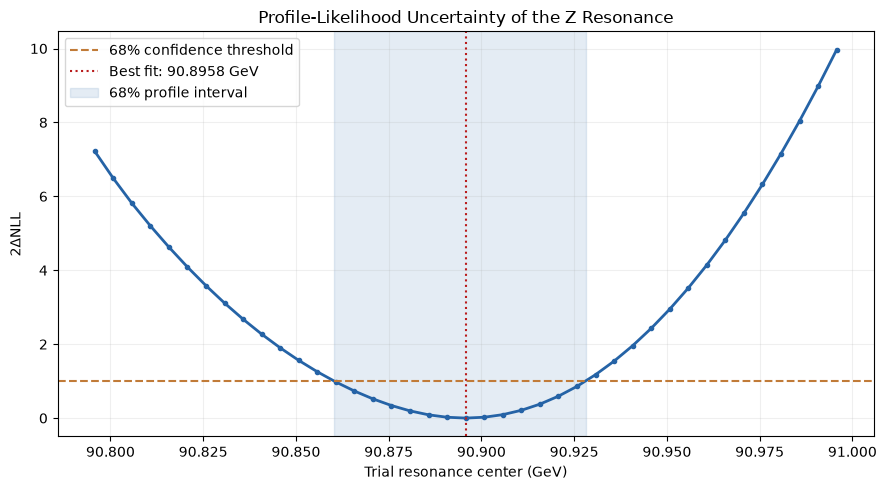

In [109]:

# Export the final profile-likelihood figure
# Run immediately AFTER the final profile-likelihood cell

from pathlib import Path
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    scan,
    q_values,
    "o-",
    color="#2563A6",
    markersize=3,
    linewidth=2
)

ax.axhline(
    1,
    color="#C17B38",
    linestyle="--",
    label="68% confidence threshold"
)

ax.axvline(
    best_mass,
    color="#B91C1C",
    linestyle=":",
    label=f"Best fit: {best_mass:.4f} GeV"
)

ax.axvspan(
    lower_limit,
    upper_limit,
    color="#2563A6",
    alpha=0.12,
    label="68% profile interval"
)

ax.set_xlabel("Trial resonance center (GeV)")
ax.set_ylabel(r"$2\Delta\mathrm{NLL}$")
ax.set_title(
    "Profile-Likelihood Uncertainty of the Z Resonance"
)

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

folder = PROJECT_ROOT / "figures"
folder.mkdir(parents=True, exist_ok=True)

fig.savefig(
    folder / "final_profile_likelihood.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    folder / "final_profile_likelihood.pdf",
    bbox_inches="tight"
)

plt.show()



## Momentum-Scale Sensitivity Test

### Objective

Investigate how a hypothetical common mass-scale change
affects the fitted Z-resonance center.

### Method

Apply assumed scale variations of -0.3%, -0.1%,
0%, +0.1%, and +0.3% to the reconstructed invariant
masses and repeat the Voigt-plus-exponential fit.

### Interpretation

This measures sensitivity to a common mass-scale
perturbation. It is not a detector calibration.

No scale factor is selected to force agreement with
the accepted Z mass.


,Scale change (%),Fitted center (GeV),Shift from baseline (MeV),Deviance/dof,Converged
0,-0.3,90.6204,-275.3315,1.1047,True
1,-0.1,90.8069,-88.9039,0.6901,True
2,0.0,90.8958,-0.0000,0.9727,True
3,0.1,90.9739,78.1876,1.0882,True
4,0.3,91.1526,256.8398,1.5826,True


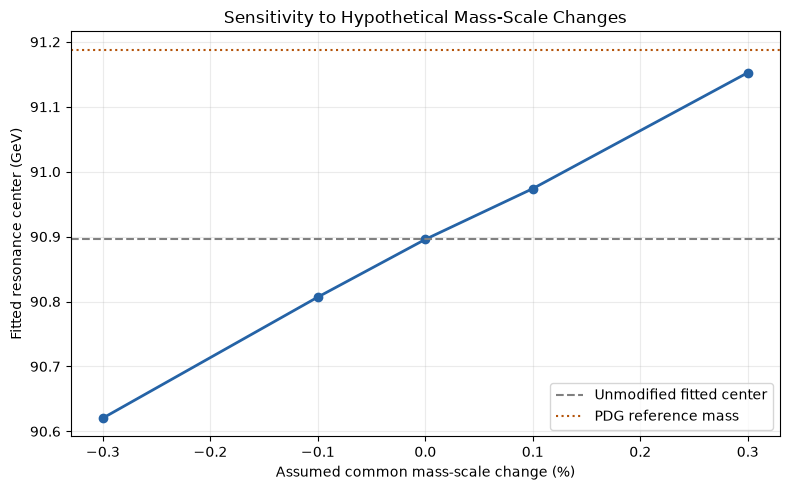

In [112]:

# Momentum-scale sensitivity using Notebook 02
# Existing function: fit_robustness()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Save the unmodified reconstructed masses
original_mass_data = (
    df2["M_alt_corrected"]
    .dropna()
    .to_numpy()
    .copy()
)

scale_variations = [-0.003, -0.001, 0, 0.001, 0.003]

scale_results = []

try:
    for epsilon in scale_variations:

        # Hypothetical common mass-scale perturbation
        mass_data = original_mass_data * (1 + epsilon)

        # Reuse the existing Voigt likelihood fitting
        fit = fit_robustness(
            bin_width=0.5,
            low_mass=85,
            high_mass=97.5
        )

        scale_results.append({
            "Scale change (%)": 100 * epsilon,
            "Fitted center (GeV)": fit["Fitted mass"],
            "Shift from baseline (MeV)":
                1000 * (
                    fit["Fitted mass"]
                    - fit_params_validated[1]
                ),
            "Deviance/dof": fit["Deviance/dof"],
            "Converged": fit["Converged"]
        })

finally:
    # Restore original masses, even if fitting fails
    mass_data = original_mass_data.copy()

scale_df = pd.DataFrame(scale_results)

display(scale_df.round(4))

# Plot the sensitivity
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    scale_df["Scale change (%)"],
    scale_df["Fitted center (GeV)"],
    "o-",
    color="#2563A6",
    linewidth=2
)

ax.axhline(
    fit_params_validated[1],
    color="gray",
    linestyle="--",
    label="Unmodified fitted center"
)

ax.axhline(
    91.1879,
    color="#B45309",
    linestyle=":",
    label="PDG reference mass"
)

ax.set_xlabel("Assumed common mass-scale change (%)")
ax.set_ylabel("Fitted resonance center (GeV)")
ax.set_title("Sensitivity to Hypothetical Mass-Scale Changes")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

out = PROJECT_ROOT / "figures"
out.mkdir(parents=True, exist_ok=True)

fig.savefig(
    out / "momentum_scale_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


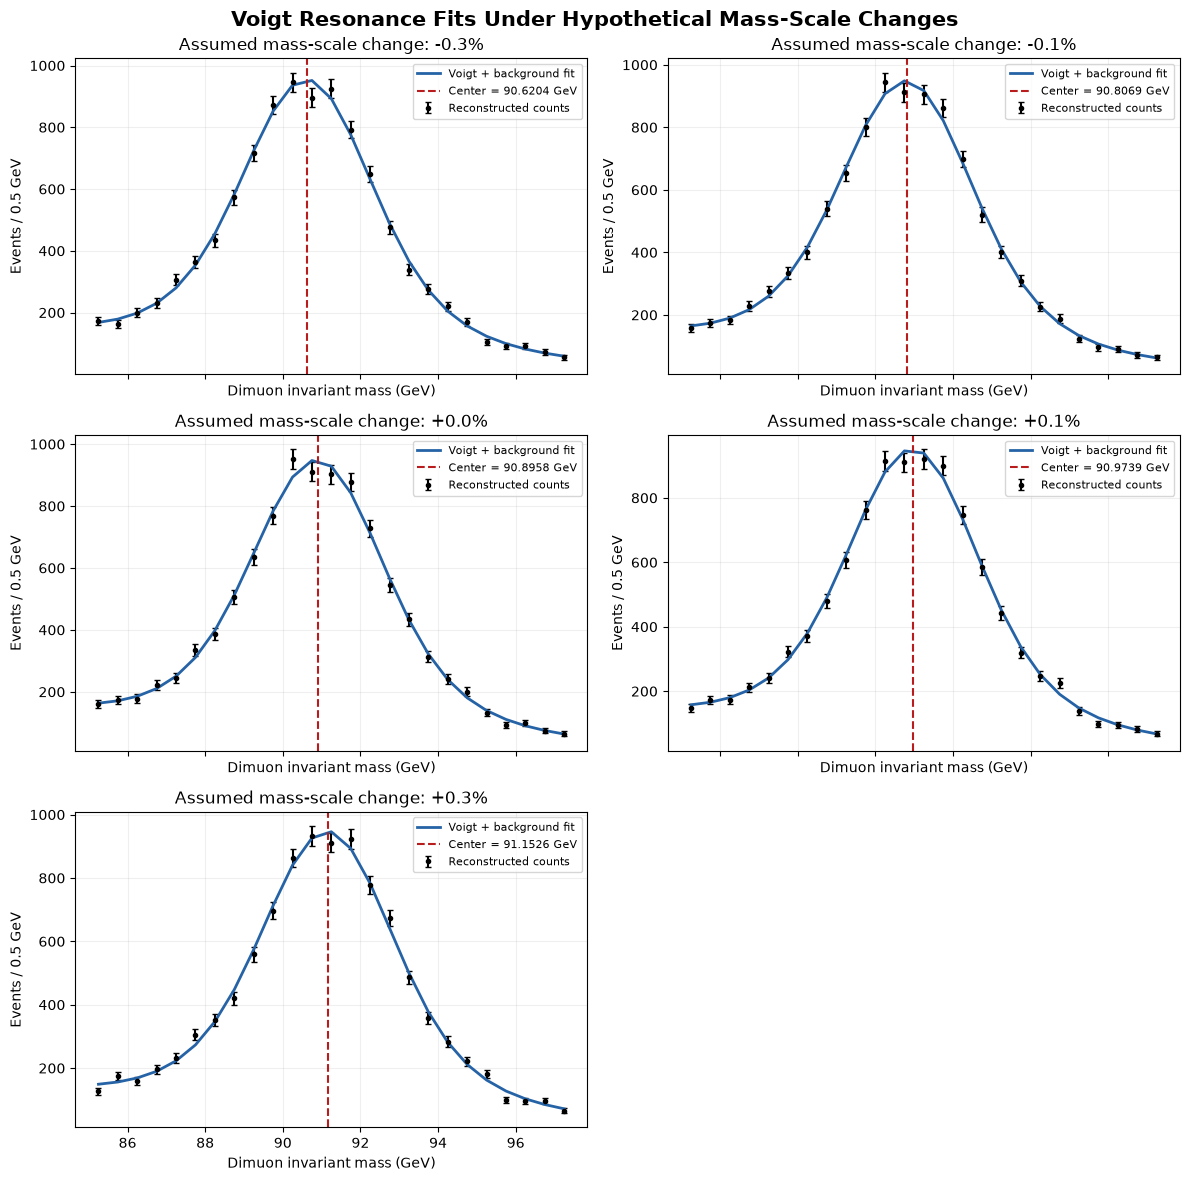


Refitted resonance centers:
-0.3% : 90.62042 GeV
-0.1% : 90.80685 GeV
+0.0% : 90.89575 GeV
+0.1% : 90.97394 GeV
+0.3% : 91.15259 GeV


In [114]:

# ===========================================================
# PLOT ALL FIVE MOMENTUM-SCALE SENSITIVITY FITS
# Notebook 02: Invariant Mass
# ===========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import voigt_profile, gammaln
from numpy.polynomial.legendre import leggauss
from pathlib import Path

original_mass = (
    df2["M_alt_corrected"].dropna().to_numpy()
)

variations = [-0.003, -0.001, 0, 0.001, 0.003]

edges_plot = np.arange(85, 98, 0.5)
centers_plot = (edges_plot[:-1] + edges_plot[1:]) / 2

nodes, weights = leggauss(12)
half = np.diff(edges_plot) / 2
points = centers_plot[:, None] + half[:, None] * nodes

parameter_scale = np.array([10000, 1, 1, 1, 100, 0.1])

scaled_bounds = [
    (lo / s, hi / s)
    for (lo, hi), s in zip(bounds_v, parameter_scale)
]

def fitted_bin_counts(params):
    S, m0, gamma, sigma, B0, k = params

    signal = S * half * np.sum(
        weights * voigt_profile(
            points - m0, sigma, gamma
        ),
        axis=1
    )

    background = half * np.sum(
        weights * (B0 / 0.5)
        * np.exp(k * (points - 91)),
        axis=1
    )

    return signal + background


def fit_scaled_spectrum(observed):

    def nll(z):
        predicted = fitted_bin_counts(
            z * parameter_scale
        )

        if np.any(predicted <= 0):
            return 1e100

        return np.sum(
            predicted
            - observed * np.log(predicted)
            + gammaln(observed + 1)
        )

    starts = [
        fit_params_validated.copy(),
        fit_params_validated.copy()
    ]
    starts[1][3] *= 1.15

    candidates = []

    for initial in starts:
        result = minimize(
            nll,
            initial / parameter_scale,
            method="L-BFGS-B",
            bounds=scaled_bounds,
            options={
                "maxiter": 15000,
                "ftol": 1e-12,
                "maxls": 50
            }
        )

        if result.success and np.isfinite(result.fun):
            candidates.append(result)

    if not candidates:
        raise RuntimeError("Scale variation fit failed")

    best = min(candidates, key=lambda r: r.fun)
    params = best.x * parameter_scale

    return params, fitted_bin_counts(params)


# Create five panels
fig, axes = plt.subplots(
    3, 2, figsize=(12, 12),
    sharex=True
)

axes = axes.flatten()

fit_plot_results = []

for i, epsilon in enumerate(variations):

    # Apply the hypothetical mass-scale change
    modified_mass = original_mass * (1 + epsilon)

    observed, _ = np.histogram(
        modified_mass,
        bins=edges_plot
    )

    params, predicted = fit_scaled_spectrum(observed)
    fitted_center = params[1]

    fit_plot_results.append(
        (100 * epsilon, fitted_center)
    )

    ax = axes[i]

    # Observed dimuon mass counts
    ax.errorbar(
        centers_plot,
        observed,
        yerr=np.sqrt(np.maximum(observed, 1)),
        fmt="o",
        color="black",
        markersize=3,
        capsize=2,
        label="Reconstructed counts"
    )

    # Reoptimized fit
    ax.plot(
        centers_plot,
        predicted,
        color="#2563A6",
        linewidth=2,
        label="Voigt + background fit"
    )

    # Fitted resonance center
    ax.axvline(
        fitted_center,
        linestyle="--",
        color="#B91C1C",
        label=f"Center = {fitted_center:.4f} GeV"
    )

    ax.set_title(
        f"Assumed mass-scale change: {100*epsilon:+.1f}%"
    )

    ax.set_ylabel("Events / 0.5 GeV")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

# Remove unused sixth panel
fig.delaxes(axes[5])

for ax in axes[:5]:
    ax.set_xlabel("Dimuon invariant mass (GeV)")

fig.suptitle(
    "Voigt Resonance Fits Under Hypothetical Mass-Scale Changes",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

# Export for report and presentation
output_dir = PROJECT_ROOT / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "mass_scale_fit_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "mass_scale_fit_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nRefitted resonance centers:")
for change, center in fit_plot_results:
    print(f"{change:+.1f}% : {center:.5f} GeV")


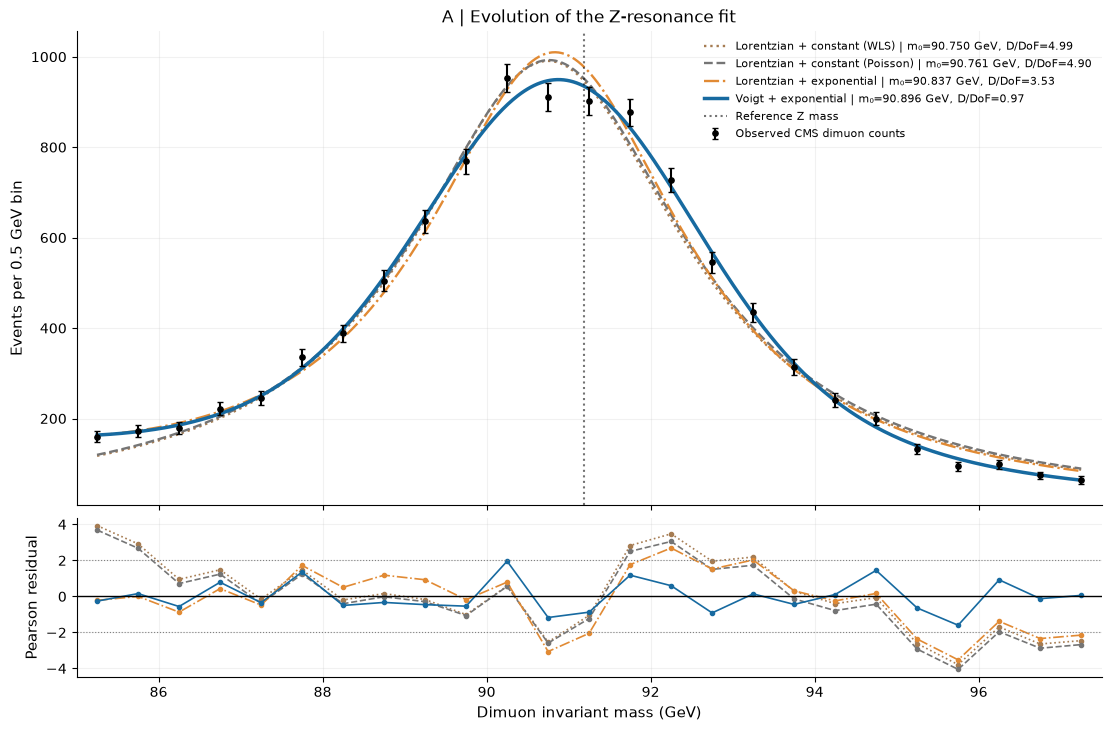

Saved: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\figures\01_full_sample_model_comparison.png and PDF


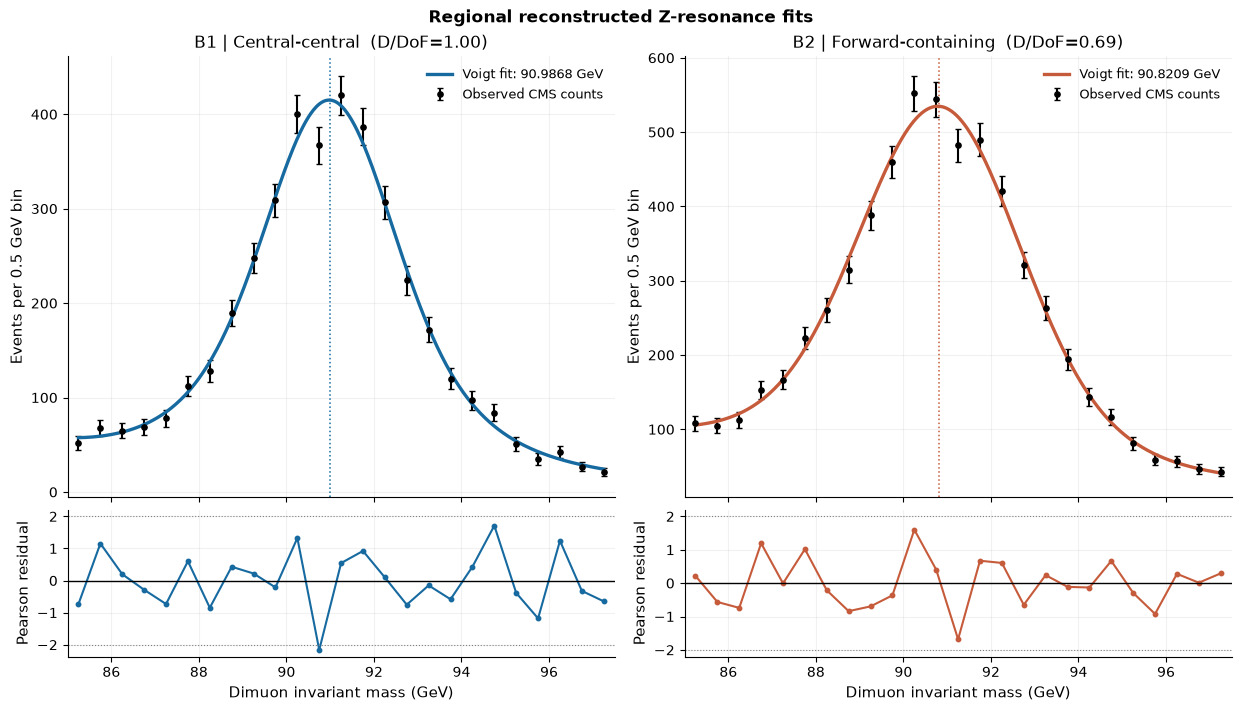

Saved: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\figures\02_detector_region_fits.png and PDF


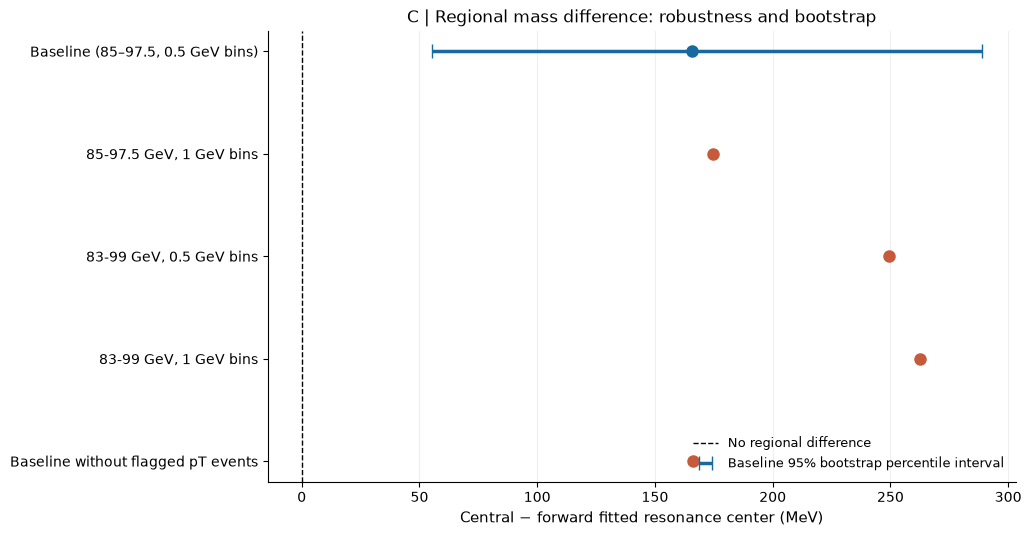

Saved: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\PH3043_ZBoson\figures\03_regional_robustness_bootstrap.png and PDF
Baseline regional difference: 165.93 MeV
Baseline 95% bootstrap percentile CI: [55.47, 288.78] MeV


In [153]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile
from numpy.polynomial.legendre import leggauss

required = ["df2", "parameters", "result", "fit_exp", "fit_params_validated",
            "verified_regions", "region_results", "differences",
            "regional_robustness", "quality_fit_table", "PROJECT_ROOT"]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError("Run earlier Notebook 02 cells first. Missing: " + ", ".join(missing))

outdir = Path(PROJECT_ROOT) / "figures"
outdir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.labelsize": 11, "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300})
C = {"wls": "#A67C52", "const": "#757575", "exp": "#E18A34",
     "voigt": "#176AA0", "central": "#176AA0", "forward": "#C65B3B"}
ref_mass = 91.1879
nodes, weights = leggauss(20)

# Count prediction for intervals centered at x with width 0.5 GeV.
# This avoids interpolating the original 25-bin model outputs.
def expected_05(x, pars, family):
    x = np.asarray(x, dtype=float)
    p = x[:, None] + 0.25 * nodes[None, :]
    if family == "voigt":
        S, m0, gamma, sigma, B0, k = pars
        density = S * voigt_profile(p-m0, sigma, gamma) + (B0/0.5)*np.exp(k*(p-91))
        return 0.25 * np.sum(density * weights, axis=1)
    if family == "exp":
        A, m0, gamma, B0, k = pars
        density = A*gamma**2/((p-m0)**2+gamma**2) + B0*np.exp(k*(p-91))
    else:
        A, m0, gamma, B = pars
        density = A*gamma**2/((p-m0)**2+gamma**2) + B
    return 0.5 * np.sum(density * weights, axis=1)

edges = np.arange(85, 98, 0.5)
centers = (edges[:-1] + edges[1:])/2
observed, _ = np.histogram(df2["M_alt_corrected"].dropna().to_numpy(), bins=edges)
x = np.linspace(85.25, 97.25, 600)

def diagnostics(counts, mu, k):
    positive = counts > 0
    term = np.zeros(len(counts), dtype=float)
    term[positive] = counts[positive]*np.log(counts[positive]/mu[positive])
    deviance = 2*np.sum(term-counts+mu)
    return deviance/(len(counts)-k)

def export(fig, filename):
    fig.savefig(outdir/(filename+".png"), dpi=300, bbox_inches="tight")
    fig.savefig(outdir/(filename+".pdf"), bbox_inches="tight")
    plt.show()
    print("Saved:", outdir/(filename+".png"), "and PDF")

# FIGURE 1: models on identical data and bins.
models = [
    ("Lorentzian + constant (WLS)", np.asarray(parameters), "constant", 4, C["wls"], ":"),
    ("Lorentzian + constant (Poisson)", np.asarray(result.x), "constant", 4, C["const"], "--"),
    ("Lorentzian + exponential", np.asarray(fit_exp.x), "exp", 5, C["exp"], "-."),
    ("Voigt + exponential", np.asarray(fit_params_validated), "voigt", 6, C["voigt"], "-"),
]
fig, ax = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True)
ax[0].errorbar(centers, observed, yerr=np.sqrt(np.maximum(observed, 1)),
               fmt="o", ms=3.8, capsize=2, color="black", label="Observed CMS dimuon counts", zorder=5)
for title, pars, family, k, color, ls in models:
    mu = expected_05(centers, pars, family)
    dev = diagnostics(observed, mu, k)
    label = f"{title} | m₀={pars[1]:.3f} GeV, D/DoF={dev:.2f}"
    ax[0].plot(x, expected_05(x, pars, family), color=color, ls=ls,
               lw=2.5 if family == "voigt" else 1.7, label=label)
    ax[1].plot(centers, (observed-mu)/np.sqrt(mu), marker="o", ms=3,
               ls=ls, lw=1.2, color=color)
ax[0].axvline(ref_mass, color="black", alpha=.55, ls=":", label="Reference Z mass")
ax[0].set(title="A | Evolution of the Z-resonance fit", ylabel="Events per 0.5 GeV bin")
ax[0].legend(fontsize=8, loc="upper right", frameon=False)
ax[1].axhline(0, color="black", lw=1)
for boundary in [-2, 2]: ax[1].axhline(boundary, color="gray", ls=":", lw=.8)
ax[1].set(xlabel="Dimuon invariant mass (GeV)", ylabel="Pearson residual", xlim=(85,97.5))
for a in ax: a.grid(alpha=.17)
export(fig, "01_full_sample_model_comparison")

# FIGURE 2: regional fit and residuals, separately scaled to the actual event counts.
fig, ax = plt.subplots(2, 2, figsize=(12.3, 7), sharex="col",
                       gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True)
for j, region in enumerate(["Central-central", "Forward-containing"]):
    pars = np.asarray(verified_regions[region]["params"])
    counts = np.asarray(verified_regions[region]["counts"])
    mu = expected_05(centers, pars, "voigt")
    color = C["central"] if j == 0 else C["forward"]
    ax[0,j].errorbar(centers, counts, yerr=np.sqrt(np.maximum(counts,1)),
                     fmt="o", ms=3.8, capsize=2, color="black", label="Observed CMS counts")
    ax[0,j].plot(x, expected_05(x, pars, "voigt"), color=color, lw=2.4,
                 label=f"Voigt fit: {pars[1]:.4f} GeV")
    ax[0,j].axvline(pars[1], color=color, lw=1.1, ls=":")
    ax[0,j].set(title=f"B{j+1} | {region}  (D/DoF={diagnostics(counts,mu,6):.2f})",
                 ylabel="Events per 0.5 GeV bin")
    ax[0,j].legend(fontsize=9, frameon=False)
    ax[1,j].plot(centers, (counts-mu)/np.sqrt(mu), "o-", color=color, ms=3.2)
    ax[1,j].axhline(0, color="black", lw=1)
    for boundary in [-2,2]: ax[1,j].axhline(boundary, color="gray", ls=":", lw=.8)
    ax[1,j].set(xlabel="Dimuon invariant mass (GeV)", ylabel="Pearson residual", xlim=(85,97.5))
    for a in ax[:,j]: a.grid(alpha=.17)
fig.suptitle("Regional reconstructed Z-resonance fits", fontweight="bold")
export(fig, "02_detector_region_fits")

# FIGURE 3: regional differences, with baseline-only bootstrap CI.
obs_delta = 1000*(verified_regions["Central-central"]["params"][1]
                  - verified_regions["Forward-containing"]["params"][1])
boot = np.asarray(differences, dtype=float)
boot = boot[np.isfinite(boot)]*1000
if len(boot)<2: raise ValueError("Bootstrap values are missing")
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
labels = ["Baseline (85–97.5, 0.5 GeV bins)"]
values = [obs_delta]
for _, r in regional_robustness.iterrows():
    if np.isclose(r["Bin width"], .5) and str(r["Fit range"]) in ("85-97.5","85.0-97.5"):
        continue
    labels.append(f"{r['Fit range']} GeV, {r['Bin width']:g} GeV bins")
    values.append(1000*float(r["Difference"]))
if "Sample" in quality_fit_table.columns:
    uf = quality_fit_table[quality_fit_table["Sample"] == "Unflagged events"]
    if len(uf):
        labels.append("Baseline without flagged pT events")
        values.append(1000*float(uf.iloc[0]["Center difference"]))
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10.2, max(4.2, .65*len(labels)+2)), constrained_layout=True)
for i, value in enumerate(values):
    ax.plot(value, y[i], "o", ms=8, color=C["voigt"] if i==0 else C["forward"])
ax.errorbar(obs_delta, 0, xerr=[[max(0,obs_delta-ci_lo)],[max(0,ci_hi-obs_delta)]],
            fmt="none", ecolor=C["voigt"], capsize=5, elinewidth=2.5,
            label="Baseline 95% bootstrap percentile interval")
ax.axvline(0, color="black", ls="--", lw=1, label="No regional difference")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlabel("Central − forward fitted resonance center (MeV)")
ax.set_title("C | Regional mass difference: robustness and bootstrap")
ax.grid(axis="x", alpha=.2)
ax.legend(loc="lower right", frameon=False, fontsize=9)
export(fig, "03_regional_robustness_bootstrap")
print(f"Baseline regional difference: {obs_delta:.2f} MeV")
print(f"Baseline 95% bootstrap percentile CI: [{ci_lo:.2f}, {ci_hi:.2f}] MeV")


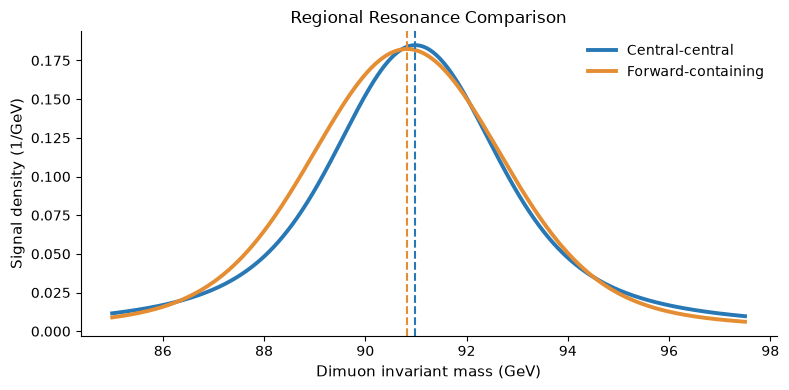

Central center: 90.986807 GeV
Forward center: 90.820875 GeV
Difference: 165.932 MeV


In [155]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile

# Retrieve the actual verified regional fit parameters
central = verified_regions["Central-central"]["params"]
forward = verified_regions["Forward-containing"]["params"]

# Fitted resonance centers
m_C = central[1]
m_F = forward[1]

# Fine mass grid for smooth curves
x = np.linspace(85, 97.5, 1500)

# Actual fitted Voigt signal profiles
central_curve = voigt_profile(
    x - m_C, central[3], central[2]
)

forward_curve = voigt_profile(
    x - m_F, forward[3], forward[2]
)

# Plot
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    x, central_curve,
    color="#2878B5",
    linewidth=2.8,
    label="Central-central"
)

ax.plot(
    x, forward_curve,
    color="#E58D32",
    linewidth=2.8,
    label="Forward-containing"
)

# Mark the fitted resonance centers
ax.axvline(m_C, color="#2878B5", linestyle="--")
ax.axvline(m_F, color="#E58D32", linestyle="--")

ax.set_xlabel("Dimuon invariant mass (GeV)")
ax.set_ylabel("Signal density (1/GeV)")

ax.set_title("Regional Resonance Comparison")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "regional_resonance_overlay.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Central center: {m_C:.6f} GeV")
print(f"Forward center: {m_F:.6f} GeV")
print(f"Difference: {(m_C-m_F)*1000:.3f} MeV")

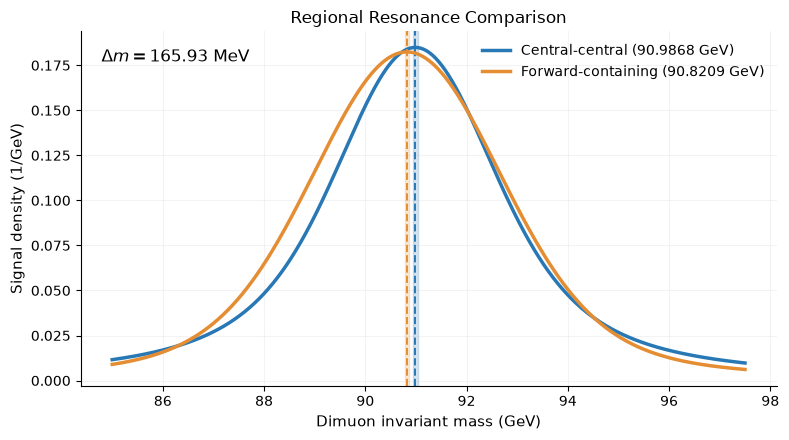

In [157]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import voigt_profile

x = np.linspace(85, 97.5, 1500)

fig, ax = plt.subplots(figsize=(8, 4.5))

colors = {
    "Central-central": "#2878B5",
    "Forward-containing": "#E58D32"
}

for region, color in colors.items():

    # Retrieve verified fit parameters
    params = verified_regions[region]["params"]

    m0 = params[1]
    gamma = params[2]
    sigma = params[3]

    # Retrieve actual 68% confidence interval
    ci = interval_results.loc[
        interval_results["Region"] == region
    ].iloc[0]

    lower = ci["Lower 68% (GeV)"]
    upper = ci["Upper 68% (GeV)"]

    # Smooth Voigt signal profile
    curve = voigt_profile(x - m0, sigma, gamma)

    ax.plot(
        x, curve,
        color=color,
        linewidth=2.5,
        label=f"{region} ({m0:.4f} GeV)"
    )

    # Fitted resonance center
    ax.axvline(
        m0, color=color,
        linestyle="--", linewidth=1.4
    )

    # Statistical uncertainty of fitted center
    ax.axvspan(
        lower, upper,
        color=color, alpha=0.20
    )

# Regional mass difference
m_C = verified_regions["Central-central"]["params"][1]
m_F = verified_regions["Forward-containing"]["params"][1]

delta_m = (m_C - m_F) * 1000

ax.text(
    0.03, 0.95,
    rf"$\Delta m = {delta_m:.2f}$ MeV",
    transform=ax.transAxes,
    va="top",
    fontsize=12
)

ax.set_xlabel("Dimuon invariant mass (GeV)")
ax.set_ylabel("Signal density (1/GeV)")
ax.set_title("Regional Resonance Comparison")

ax.legend(frameon=False)
ax.grid(alpha=0.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "regional_comparison_uncertainty.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "regional_comparison_uncertainty.pdf",
    bbox_inches="tight"
)

plt.show()

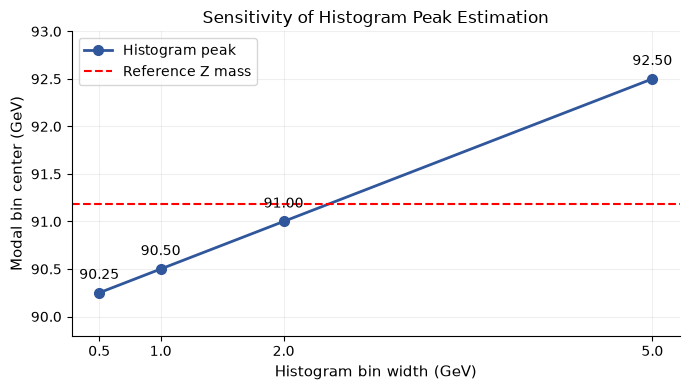

In [159]:
import numpy as np
import matplotlib.pyplot as plt

bin_widths = [0.5, 1, 2, 5]
peak_masses = [90.25, 90.50, 91.00, 92.50]

plt.figure(figsize=(7, 4))

plt.plot(
    bin_widths, peak_masses,
    "o-", color="#30569B",
    linewidth=2, markersize=7,
    label="Histogram peak"
)

plt.axhline(
    91.1879,
    color="red",
    linestyle="--",
    label="Reference Z mass"
)

for x, y in zip(bin_widths, peak_masses):
    plt.annotate(
        f"{y:.2f}",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

plt.xticks(bin_widths)
plt.xlabel("Histogram bin width (GeV)")
plt.ylabel("Modal bin center (GeV)")
plt.title("Sensitivity of Histogram Peak Estimation")
plt.ylim(89.8, 93)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "bin_width_sensitivity.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

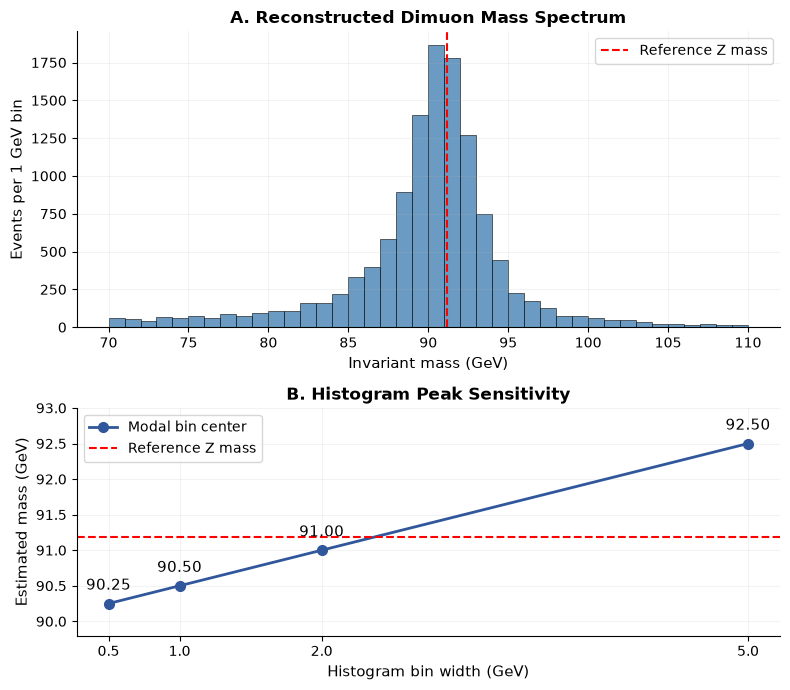

Total peak variation: 2.25 GeV


In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actual reconstructed masses
mass = df2["M_alt_corrected"].dropna().to_numpy()

reference_mass = 91.1879
bin_widths = [0.5, 1, 2, 5]

# Calculate peak position for each bin width
peak_masses = []

for width in bin_widths:

    edges = np.arange(70, 110 + width, width)
    counts, _ = np.histogram(mass, bins=edges)

    peak_idx = np.argmax(counts)

    peak_center = (
        edges[peak_idx] + edges[peak_idx + 1]
    ) / 2

    peak_masses.append(peak_center)

# Calculate total variation
variation = max(peak_masses) - min(peak_masses)

# Create figure
fig, axes = plt.subplots(
    2, 1, figsize=(8, 7),
    gridspec_kw={"height_ratios": [1.3, 1]},
    facecolor="white"
)

# A: Actual reconstructed mass histogram
axes[0].hist(
    mass,
    bins=np.arange(70, 111, 1),
    color="steelblue",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8
)

axes[0].axvline(
    reference_mass,
    color="red",
    linestyle="--",
    label="Reference Z mass"
)

axes[0].set_title(
    "A. Reconstructed Dimuon Mass Spectrum",
    fontweight="bold"
)

axes[0].set_xlabel("Invariant mass (GeV)")
axes[0].set_ylabel("Events per 1 GeV bin")
axes[0].legend()
axes[0].grid(alpha=0.15)

# B: Histogram peak sensitivity
axes[1].plot(
    bin_widths,
    peak_masses,
    "o-",
    color="#30569B",
    linewidth=2,
    markersize=7,
    label="Modal bin center"
)

axes[1].axhline(
    reference_mass,
    color="red",
    linestyle="--",
    label="Reference Z mass"
)

# Mark actual peak values
for x, y in zip(bin_widths, peak_masses):

    axes[1].annotate(
        f"{y:.2f}",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=11
    )

axes[1].set_title(
    "B. Histogram Peak Sensitivity",
    fontweight="bold"
)

axes[1].set_xticks(bin_widths)
axes[1].set_ylim(89.8, 93)
axes[1].set_xlabel("Histogram bin width (GeV)")
axes[1].set_ylabel("Estimated mass (GeV)")
axes[1].legend()
axes[1].grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    "mass_spectrum_and_binning.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Total peak variation: {variation:.2f} GeV")